# Bitcoin Overnight Signals für den QQQ-Eröffnungsgap

Wir untersuchen, ob Bitcoin-Aktivität ausserhalb der regulären
US-Handelszeit zusammen mit Sentiment- und Makroindikatoren zusätzliche
Information für die Richtung des nächsten QQQ-Eröffnungsgaps enthält.

Eine Beobachtung entspricht einem QQQ-Handelstag. Das Bitcoin-Fenster
beginnt mit dem Ende der vorherigen regulären Nasdaq-Sitzung und endet
um 09:00 Uhr New Yorker Zeit. Damit liegt der Informations-Cutoff 30
Minuten vor der regulären QQQ-Eröffnung um 09:30 Uhr.

**Aktueller Notebook-Stand:** reproduzierbares Setup, Datenbeschaffung,
zeitliche Ausrichtung, Leakage-Prüfungen, explorative Datenanalyse,
Expanding-window-Folds, historische Mehrheitsbaseline und logistische
Regression ohne und mit Bitcoin. Die weiteren Modelle werden
anschliessend im selben Notebook ergänzt.

## 1. Aufgabe und Untersuchungsdesign

### Erklärung

Für den QQQ-Handelstag (t) berechnen wir den numerischen
Eröffnungsgap als logarithmische Rendite vom Schluss der vorherigen
regulären Sitzung bis zum Open des Zieltags:

$$
y_t = r^{gap}_t
= \log\left(\frac{Open^{QQQ}_t}{Close^{QQQ}_{t-1}}\right).
$$

Die primäre Zielvariable ist die Richtung:

$$
Direction_t = \mathbb{1}(y_t > 0).
$$

`1` bedeutet, dass QQQ höher eröffnet; `0` bezeichnet eine gleich hohe
oder tiefere Eröffnung. Der numerische Gap bleibt für die EDA und die
spätere Chronos-2-Prognose erhalten.

Wir vergleichen später für jede Modellklasse zwei Feature-Sets:

1. **Kontrolle:** QQQ-Historie, Fear & Greed, VIX, DXY und Kalender.
2. **Mit Bitcoin:** dieselben Variablen plus BTC-Overnight-Merkmale.

Nur der Unterschied zwischen diesen Varianten misst den zusätzlichen
Informationsgehalt von Bitcoin. Wir untersuchen eine Prognosebeziehung,
keine Kausalität und keine fertige Handelsstrategie.

### Zeitliche Evaluation

- Entwicklung und Expanding-window-Validierung: bis Ende 2025.
- Validierungsjahre: 2021 bis 2025.
- Finaler, in der EDA unberührter Holdout: ab 1. Januar 2026.

## 2. Setup

### Erklärung

Alle zentralen Parameter stehen sichtbar in einer Zelle. Marktzeiten
werden in `America/New_York` definiert und für die Berechnung nach UTC
konvertiert. `exchange_calendars` liefert reguläre Nasdaq-Sitzungen,
Feiertage und verkürzte Handelstage. Die tabellarische Verarbeitung
läuft auf der CPU; MPS wird erst für Chronos-2 relevant.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from zipfile import ZipFile
import os
import platform
import random
import warnings

import exchange_calendars as xcals
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import yfinance as yf

# Keep all configuration visible and reproducible
RANDOM_SEED = 42
START_DATE = "2018-02-01"
DATA_END_DATE = "2026-07-01"  # Exclusive and fully completed
HOLDOUT_START = pd.Timestamp("2026-01-01")
VALIDATION_YEARS = [2021, 2022, 2023, 2024, 2025]
FORECAST_TIMEZONE = "America/New_York"
FORECAST_HOUR = 9
BINANCE_SYMBOL = "BTCUSDT"
BINANCE_INTERVAL = "1h"
CHRONOS_MODEL_ID = "amazon/chronos-2"
XGBOOST_N_JOBS = 1
os.environ["OMP_NUM_THREADS"] = str(XGBOOST_N_JOBS)

# Validate the fixed data range
data_end_timestamp = pd.Timestamp(DATA_END_DATE)
current_utc_day = pd.Timestamp.now(tz="UTC").normalize().tz_localize(None)
assert data_end_timestamp <= current_utc_day

# Resolve paths from the repository root or the notebooks folder
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
BINANCE_CACHE_DIR = RAW_DATA_DIR / "binance" / BINANCE_SYMBOL / BINANCE_INTERVAL
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
BINANCE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Make random operations reproducible
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Use Viridis consistently for tables and plots
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)
VIRIDIS = plt.colormaps["viridis"]
COLORS = {
    "qqq": VIRIDIS(0.12),
    "btc": VIRIDIS(0.38),
    "fear_greed": VIRIDIS(0.58),
    "vix": VIRIDIS(0.74),
    "dxy": VIRIDIS(0.90),
}

# Detect Apple Silicon acceleration for the later foundation model
try:
    import torch

    TORCH_VERSION = torch.__version__
    DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
except ImportError:
    torch = None
    TORCH_VERSION = "nicht installiert"
    DEVICE = "cpu"


def installed_version(package_name):
    # Return one version string for the reproducibility table
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "nicht installiert"


environment_table = pd.DataFrame(
    {
        "Komponente": [
            "Python",
            "Betriebssystem",
            "Prozessor",
            "PyTorch",
            "Chronos-Gerät",
            "Forecast-Zeitzone",
            "Informations-Cutoff",
            "Erster Datentag",
            "Exklusiver Datenstichtag",
            "Holdout ab",
            "pandas",
            "exchange-calendars",
            "yfinance",
            "XGBoost",
            "chronos-forecasting",
        ],
        "Wert": [
            platform.python_version(),
            platform.platform(),
            platform.machine(),
            TORCH_VERSION,
            DEVICE,
            FORECAST_TIMEZONE,
            "09:00 Uhr ET",
            START_DATE,
            DATA_END_DATE,
            HOLDOUT_START.date(),
            installed_version("pandas"),
            installed_version("exchange-calendars"),
            installed_version("yfinance"),
            installed_version("xgboost"),
            installed_version("chronos-forecasting"),
        ],
    }
)
display(environment_table)

,Komponente,Wert
0,Python,3.11.13
1,Betriebssystem,macOS-26.5.2-arm64-arm-64bit
2,Prozessor,arm64
3,PyTorch,2.13.0
4,Chronos-Gerät,mps
5,Forecast-Zeitzone,America/New_York
6,Informations-Cutoff,09:00 Uhr ET
7,Erster Datentag,2018-02-01
8,Exklusiver Datenstichtag,2026-07-01
9,Holdout ab,2026-01-01


### Interpretation

Die Tabelle dokumentiert den festen Informationsstand und die
tatsächlich verwendete Umgebung. Der Prognose-Cutoff liegt immer vor
dem Ziel-Open. Dadurch können spätere Modellprognosen realistisch und
ohne Zugriff auf den QQQ-Eröffnungskurs erzeugt werden.

## 3. Daten beschaffen und Rohdaten prüfen

### Erklärung

Wir laden stündliche `BTCUSDT`-Kerzen aus dem öffentlichen
Binance-Archiv. QQQ, VIX und DXY stammen über `yfinance` von Yahoo
Finance; Fear & Greed beziehen wir über die API von Alternative.me.
Nach dem ersten erfolgreichen Lauf werden die Rohdaten lokal
zwischengespeichert.

| Inhalt | Quelle / Symbol | Verwendung |
|---|---|---|
| Bitcoin OHLCV | Binance `BTCUSDT`, 1 Stunde | Overnight-Merkmale |
| Nasdaq-100 ETF | Yahoo `QQQ` | Ziel und eigene Historie |
| Volatilitätsindex | Yahoo `^VIX` | Marktunsicherheit |
| US-Dollar-Index | Yahoo `DX-Y.NYB` | Makroumfeld |
| Fear & Greed | Alternative.me | Krypto-Sentiment |

Binance verwendet in älteren Archivdateien Millisekunden und in
neueren Dateien teilweise Mikrosekunden. Die Einheit wird pro Datei
anhand der Grössenordnung erkannt.

In [2]:
BINANCE_COLUMNS = [
    "open_time",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "close_time",
    "quote_volume",
    "trade_count",
    "taker_buy_base_volume",
    "taker_buy_quote_volume",
    "ignore",
]


def parse_binance_time(values):
    # Detect millisecond or microsecond Unix timestamps per archive file
    numeric_values = pd.to_numeric(values, errors="coerce")
    non_missing = numeric_values.dropna()
    assert not non_missing.empty, "Binance-Datei ohne gültige Zeitstempel"
    unit = "us" if non_missing.median() >= 10**14 else "ms"
    return pd.to_datetime(numeric_values, unit=unit, utc=True)


def read_binance_month(month_start):
    # Reuse the original monthly ZIP so each download stays traceable
    month_label = month_start.strftime("%Y-%m")
    filename = f"{BINANCE_SYMBOL}-{BINANCE_INTERVAL}-{month_label}.zip"
    cache_path = BINANCE_CACHE_DIR / filename
    url = (
        "https://data.binance.vision/data/spot/monthly/klines/"
        f"{BINANCE_SYMBOL}/{BINANCE_INTERVAL}/{filename}"
    )

    if not cache_path.exists():
        response = requests.get(
            url,
            headers={"User-Agent": "CSP1 educational time-series project"},
            timeout=60,
        )
        response.raise_for_status()
        cache_path.write_bytes(response.content)

    # Read the CSV directly from the ZIP container
    with ZipFile(cache_path) as archive:
        csv_names = [name for name in archive.namelist() if name.endswith(".csv")]
        assert len(csv_names) == 1, f"Unerwarteter Inhalt in {filename}"
        with archive.open(csv_names[0]) as stream:
            frame = pd.read_csv(stream, header=None, names=BINANCE_COLUMNS)

    frame["open_time"] = parse_binance_time(frame["open_time"])
    frame["close_time"] = parse_binance_time(frame["close_time"])
    frame = frame.dropna(subset=["open_time", "close_time"]).copy()
    frame = frame.loc[frame["close_time"] > frame["open_time"]].copy()
    numeric_columns = ["open", "high", "low", "close", "volume"]
    frame[numeric_columns] = frame[numeric_columns].apply(
        pd.to_numeric, errors="coerce"
    )
    return frame[["open_time", "close_time", *numeric_columns]]


def validate_bitcoin_hourly(frame):
    # Check the market-data contract before feature construction
    assert not frame.empty, "Bitcoin: keine Daten"
    assert frame.index.is_monotonic_increasing, "Bitcoin: Zeit nicht sortiert"
    assert frame.index.is_unique, "Bitcoin: doppelte Stunden"
    assert frame.notna().all().all(), "Bitcoin: fehlende Werte"
    assert np.isfinite(
        frame[["open", "high", "low", "close", "volume"]].to_numpy()
    ).all(), "Bitcoin: nicht endliche Werte"
    assert (frame["close_time"] > frame.index).all()
    assert (frame[["open", "high", "low", "close"]] > 0).all().all()
    assert (frame["volume"] >= 0).all()
    assert (
        frame["high"] >= frame[["open", "close", "low"]].max(axis=1)
    ).all()
    assert (
        frame["low"] <= frame[["open", "close", "high"]].min(axis=1)
    ).all()


def load_binance_hourly():
    # Prefer one compact combined cache after the first successful run
    combined_cache = (
        RAW_DATA_DIR
        / f"btc_{BINANCE_SYMBOL}_{BINANCE_INTERVAL}_{START_DATE}_{DATA_END_DATE}.csv.gz"
    )
    if combined_cache.exists():
        cached = pd.read_csv(combined_cache)
        required_cache_columns = {
            "open_time", "close_time", "open", "high", "low", "close", "volume"
        }
        if required_cache_columns.issubset(cached.columns):
            cached["open_time"] = pd.to_datetime(
                cached["open_time"], utc=True, format="mixed"
            )
            cached["close_time"] = pd.to_datetime(
                cached["close_time"], utc=True, format="mixed"
            )
            cached = cached.set_index("open_time").sort_index()
            validate_bitcoin_hourly(cached)
            return cached

    # Download every complete calendar month in the fixed range
    first_month = pd.Timestamp(START_DATE).to_period("M").start_time
    last_month = (pd.Timestamp(DATA_END_DATE) - pd.Timedelta(days=1)).to_period(
        "M"
    ).start_time
    month_starts = pd.date_range(first_month, last_month, freq="MS")
    monthly_frames = [read_binance_month(month) for month in month_starts]

    frame = pd.concat(monthly_frames, ignore_index=True)
    frame = frame.set_index("open_time").sort_index()
    frame = frame.loc[
        (frame.index >= pd.Timestamp(START_DATE, tz="UTC"))
        & (frame.index < pd.Timestamp(DATA_END_DATE, tz="UTC"))
    ]
    validate_bitcoin_hourly(frame)
    frame.reset_index().to_csv(combined_cache, index=False, compression="gzip")
    return frame


YAHOO_SERIES = {
    "qqq": {
        "ticker": "QQQ",
        "columns": ["Open", "High", "Low", "Close", "Volume"],
    },
    "vix": {"ticker": "^VIX", "columns": ["Close"]},
    "dxy": {"ticker": "DX-Y.NYB", "columns": ["Close"]},
}


def validate_yahoo_frame(frame, series_name):
    # Keep source checks simple, explicit and visible
    assert not frame.empty, f"{series_name}: keine Daten"
    assert frame.index.is_monotonic_increasing, f"{series_name}: nicht sortiert"
    assert frame.index.is_unique, f"{series_name}: doppelte Tage"
    assert frame.notna().all().all(), f"{series_name}: fehlende Rohwerte"
    assert np.isfinite(frame.select_dtypes("number")).all().all()
    assert frame.index.min() >= pd.Timestamp(START_DATE)
    assert frame.index.max() < pd.Timestamp(DATA_END_DATE)
    assert (frame.select_dtypes("number") >= 0).all().all()

    if series_name == "qqq":
        assert (
            frame["qqq_high"]
            >= frame[["qqq_open", "qqq_close", "qqq_low"]].max(axis=1)
        ).all()
        assert (
            frame["qqq_low"]
            <= frame[["qqq_open", "qqq_close", "qqq_high"]].min(axis=1)
        ).all()


def load_yahoo_series(series_name, ticker, columns):
    # Use adjusted OHLC consistently across all sessions
    safe_ticker = ticker.replace("^", "").replace("=", "_").replace(".", "_")
    cache_path = (
        RAW_DATA_DIR
        / f"{series_name}_{safe_ticker}_{START_DATE}_{DATA_END_DATE}.csv"
    )

    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        validate_yahoo_frame(cached, series_name)
        return cached

    downloaded = yf.download(
        ticker,
        start=START_DATE,
        end=DATA_END_DATE,
        interval="1d",
        auto_adjust=True,
        repair=False,
        progress=False,
        threads=False,
        timeout=30,
        multi_level_index=False,
    )
    if downloaded.empty:
        raise RuntimeError(f"Keine Yahoo-Daten für {ticker} erhalten")

    downloaded.index = pd.to_datetime(downloaded.index).tz_localize(None).normalize()
    downloaded.index.name = "date"
    frame = downloaded.loc[:, columns].copy()
    frame.columns = [
        f"{series_name}_{column.lower().replace(' ', '_')}" for column in columns
    ]
    validate_yahoo_frame(frame, series_name)
    frame.reset_index().to_csv(cache_path, index=False)
    return frame


def load_fear_greed():
    # Keep publication timestamps for a leakage-safe as-of merge
    cache_path = RAW_DATA_DIR / f"fear_greed_{START_DATE}_{DATA_END_DATE}.csv"
    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["timestamp_utc"])
        cached["timestamp_utc"] = pd.to_datetime(cached["timestamp_utc"], utc=True)
        return cached.sort_values("timestamp_utc")

    response = requests.get(
        "https://api.alternative.me/fng/",
        params={"limit": 0, "format": "json"},
        headers={"User-Agent": "CSP1 educational time-series project"},
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()
    assert "data" in payload and payload["data"], "Fear & Greed API ohne Daten"

    frame = pd.DataFrame(payload["data"])
    frame["timestamp_utc"] = pd.to_datetime(
        frame["timestamp"].astype("int64"), unit="s", utc=True
    )
    frame["fear_greed"] = pd.to_numeric(frame["value"], errors="coerce")
    frame = frame.loc[
        (frame["timestamp_utc"] >= pd.Timestamp(START_DATE, tz="UTC"))
        & (frame["timestamp_utc"] < pd.Timestamp(DATA_END_DATE, tz="UTC")),
        ["timestamp_utc", "fear_greed"],
    ].sort_values("timestamp_utc")

    assert frame["timestamp_utc"].is_unique
    assert frame["fear_greed"].between(0, 100).all()
    frame.to_csv(cache_path, index=False)
    return frame

In [3]:
# Download or reuse each source in the fixed data range
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    btc_hourly = load_binance_hourly()
    yahoo_data = {
        name: load_yahoo_series(name, settings["ticker"], settings["columns"])
        for name, settings in YAHOO_SERIES.items()
    }
    fear_greed = load_fear_greed()

qqq = yahoo_data["qqq"]
vix = yahoo_data["vix"]
dxy = yahoo_data["dxy"]

# Count material BTC gaps without filling them
observed_hour_gaps = btc_hourly.index.to_series().diff() / pd.Timedelta(hours=1)
missing_btc_hours = int(
    np.floor((observed_hour_gaps[observed_hour_gaps > 1.5] - 1).sum())
)

source_summary = pd.DataFrame(
    [
        {
            "Quelle": "Bitcoin (Binance, 1h)",
            "Erste Beobachtung": btc_hourly.index.min(),
            "Letzte Beobachtung": btc_hourly.index.max(),
            "Zeilen": len(btc_hourly),
            "Duplikate": int(btc_hourly.index.duplicated().sum()),
            "Fehlende Werte": int(btc_hourly.isna().sum().sum()),
            "Erwartete Lücken": missing_btc_hours,
        },
        *[
            {
                "Quelle": name.upper(),
                "Erste Beobachtung": frame.index.min(),
                "Letzte Beobachtung": frame.index.max(),
                "Zeilen": len(frame),
                "Duplikate": int(frame.index.duplicated().sum()),
                "Fehlende Werte": int(frame.isna().sum().sum()),
                "Erwartete Lücken": "Wochenenden/Feiertage",
            }
            for name, frame in yahoo_data.items()
        ],
        {
            "Quelle": "Fear & Greed",
            "Erste Beobachtung": fear_greed["timestamp_utc"].min(),
            "Letzte Beobachtung": fear_greed["timestamp_utc"].max(),
            "Zeilen": len(fear_greed),
            "Duplikate": int(fear_greed["timestamp_utc"].duplicated().sum()),
            "Fehlende Werte": int(fear_greed.isna().sum().sum()),
            "Erwartete Lücken": "As-of-Merge",
        },
    ]
)
display(source_summary)
btc_preview = btc_hourly.head(3).copy()
btc_preview_numeric = btc_preview.select_dtypes(include="number").columns
btc_preview[btc_preview_numeric] = btc_preview[btc_preview_numeric].round(2)
display(btc_preview)
display(qqq.head(3).round(2))

,Quelle,Erste Beobachtung,Letzte Beobachtung,Zeilen,Duplikate,Fehlende Werte,Erwartete Lücken
0,"Bitcoin (Binance, 1h)",2018-02-01 00:00:00+00:00,2026-06-30 23:00:00+00:00,73608,0,0,120
1,QQQ,2018-02-01 00:00:00,2026-06-30 00:00:00,2113,0,0,Wochenenden/Feiertage
2,VIX,2018-02-01 00:00:00,2026-06-30 00:00:00,2114,0,0,Wochenenden/Feiertage
3,DXY,2018-02-01 00:00:00,2026-06-30 00:00:00,2115,0,0,Wochenenden/Feiertage
4,Fear & Greed,2018-02-01 00:00:00+00:00,2026-06-30 00:00:00+00:00,3068,0,0,As-of-Merge


,close_time,open,high,low,close,volume
open_time,,,,,,
2018-02-01 00:00:00+00:00,2018-02-01 00:59:59.999000+00:00,10285.10,10335.00,10215.07,10263.18,594.44
2018-02-01 01:00:00+00:00,2018-02-01 01:59:59.999000+00:00,10263.18,10328.98,10216.00,10247.49,591.52
2018-02-01 02:00:00+00:00,2018-02-01 02:59:59.999000+00:00,10249.43,10317.73,10176.89,10199.61,479.41


,qqq_open,qqq_high,qqq_low,qqq_close,qqq_volume
date,,,,,
2018-02-01,159.16,160.70,158.51,159.02,38037900
2018-02-02,158.40,158.78,155.72,155.85,68478100
2018-02-05,154.39,156.93,149.59,149.71,105372200


In [4]:
# Derive the interpretation from validated source frames
btc_rows_display = f"{len(btc_hourly):,}".replace(",", "'")
qqq_rows_display = f"{len(qqq):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Alle Quellen wurden erfolgreich geladen und bestehen die Prüfungen auf
Chronologie, eindeutige Zeitstempel, fehlende Werte und plausible
Wertebereiche. Wir verfügen über **{btc_rows_display} Bitcoin-Stunden**
und **{qqq_rows_display} QQQ-Handelstage**. Im Bitcoin-Stundenraster
fehlen **{missing_btc_hours} Zeitstempel**. Solche Lücken werden nicht
interpoliert; ein betroffenes Overnight-Fenster wird später als
unvollständig markiert und entfernt.
        '''
    )
)


### Interpretation

Alle Quellen wurden erfolgreich geladen und bestehen die Prüfungen auf
Chronologie, eindeutige Zeitstempel, fehlende Werte und plausible
Wertebereiche. Wir verfügen über **73'608 Bitcoin-Stunden**
und **2'113 QQQ-Handelstage**. Im Bitcoin-Stundenraster
fehlen **120 Zeitstempel**. Solche Lücken werden nicht
interpoliert; ein betroffenes Overnight-Fenster wird später als
unvollständig markiert und entfernt.
        

### Quellen und methodische Grundlagen

- [Binance Public Data](https://data.binance.vision/) für stündliche
  `BTCUSDT`-OHLCV-Daten.
- [Yahoo Finance über yfinance](https://ranaroussi.github.io/yfinance/)
  für QQQ, VIX und DXY.
- [Alternative.me Fear & Greed API](https://alternative.me/crypto/fear-and-greed-index/).
- [exchange_calendars](https://github.com/gerrymanoim/exchange_calendars)
  für Nasdaq-Sitzungen, Feiertage und verkürzte Handelstage.
- Hyndman und Athanasopoulos,
  [Forecasting: Principles and Practice](https://otexts.com/fpp3/).
- [Marco Peixeiro: Statistical forecasting baseline notebook](https://github.com/marcopeix/youtube_tutorials/blob/main/YT_03_forecasting_stats.ipynb).
- Chen und Guestrin (2016),
  [XGBoost](https://doi.org/10.1145/2939672.2939785).
- [Chronos-2 Technical Report](https://arxiv.org/abs/2510.15821) und
  [offizielles Chronos-Repository](https://github.com/amazon-science/chronos-forecasting).
- [MachineLearningMastery: 2026 Time Series Toolkit](https://machinelearningmastery.com/the-2026-time-series-toolkit-5-foundation-models-for-autonomous-forecasting/)
  als ergänzender Überblick.

Die Marktdaten verwenden wir ausschliesslich für Ausbildung und
Forschung unter den jeweiligen Nutzungsbedingungen.

## 4. Nasdaq-Sitzungen und QQQ-Ziel konstruieren

### Erklärung

Eine Zeile verbindet zwei aufeinanderfolgende QQQ-Handelstage. Für den
Zieltages (t) verwenden wir den Schlusskurs der vorherigen regulären
Sitzung (t-1) und den offiziellen QQQ-Open von (t).

Der Börsenkalender liefert die tatsächlichen UTC-Zeitpunkte für
Sitzungsschluss und -eröffnung. Damit werden Feiertage und verkürzte
Sitzungen korrekt behandelt. QQQ-Historienmerkmale werden auf der
vorherigen abgeschlossenen Sitzung gemessen. Gap-Lags werden zusätzlich
um eine Beobachtung verschoben, sodass der aktuelle Ziel-Gap niemals in
seinen eigenen Features vorkommt.

In [5]:
# Build the official Nasdaq schedule for all QQQ dates
nasdaq_calendar = xcals.get_calendar("XNAS")
schedule = nasdaq_calendar.schedule.loc[
    pd.Timestamp(START_DATE): pd.Timestamp(DATA_END_DATE) - pd.Timedelta(days=1),
    ["open", "close"],
].copy()
schedule.index = pd.to_datetime(schedule.index).tz_localize(None).normalize()

missing_schedule_dates = qqq.index.difference(schedule.index)
assert missing_schedule_dates.empty, (
    f"QQQ-Tage ohne Nasdaq-Kalender: {missing_schedule_dates.tolist()}"
)

# Calculate QQQ history only from completed sessions
qqq_history = qqq.copy()
qqq_history["qqq_return_1d"] = np.log(
    qqq_history["qqq_close"] / qqq_history["qqq_close"].shift(1)
)
qqq_history["qqq_momentum_5d"] = np.log(
    qqq_history["qqq_close"] / qqq_history["qqq_close"].shift(5)
)
qqq_history["qqq_volatility_20d"] = (
    qqq_history["qqq_return_1d"].rolling(20).std() * np.sqrt(252)
)

weekday_names = {
    0: "Montag",
    1: "Dienstag",
    2: "Mittwoch",
    3: "Donnerstag",
    4: "Freitag",
}

target_rows = []
for position in range(1, len(qqq_history)):
    # Pair every target session with the previous observed QQQ session
    previous_date = qqq_history.index[position - 1]
    target_date = qqq_history.index[position]
    previous_row = qqq_history.iloc[position - 1]
    target_row = qqq_history.iloc[position]

    previous_close_utc = schedule.loc[previous_date, "close"]
    target_open_utc = schedule.loc[target_date, "open"]
    forecast_cutoff_local = (
        pd.Timestamp(target_date).tz_localize(FORECAST_TIMEZONE)
        + pd.Timedelta(hours=FORECAST_HOUR)
    )
    forecast_cutoff_utc = forecast_cutoff_local.tz_convert("UTC")
    gap_log_return = np.log(target_row["qqq_open"] / previous_row["qqq_close"])

    target_rows.append(
        {
            "previous_session_date": previous_date,
            "target_session_date": target_date,
            "previous_close_utc": previous_close_utc,
            "forecast_cutoff_utc": forecast_cutoff_utc,
            "target_open_utc": target_open_utc,
            "overnight_hours": (
                forecast_cutoff_utc - previous_close_utc
            ) / pd.Timedelta(hours=1),
            "target_weekday": weekday_names[target_date.dayofweek],
            "target_is_monday": int(target_date.dayofweek == 0),
            "qqq_previous_close": previous_row["qqq_close"],
            "qqq_target_open": target_row["qqq_open"],
            "qqq_gap_log_return": gap_log_return,
            "qqq_gap_percent": 100 * np.expm1(gap_log_return),
            "qqq_gap_direction": int(gap_log_return > 0),
            "qqq_return_1d": previous_row["qqq_return_1d"],
            "qqq_momentum_5d": previous_row["qqq_momentum_5d"],
            "qqq_volatility_20d": previous_row["qqq_volatility_20d"],
        }
    )

target_table = pd.DataFrame(target_rows)

# Shift target history so only previously observed gaps become features
target_table["qqq_gap_lag_1"] = target_table["qqq_gap_log_return"].shift(1)
target_table["qqq_gap_mean_5"] = (
    target_table["qqq_gap_log_return"].shift(1).rolling(5).mean()
)

# Enforce the timing contract before adding Bitcoin
assert target_table["target_session_date"].is_monotonic_increasing
assert target_table["target_session_date"].is_unique
assert (
    target_table["previous_session_date"] < target_table["target_session_date"]
).all()
assert (
    target_table["previous_close_utc"] < target_table["forecast_cutoff_utc"]
).all()
assert (
    target_table["forecast_cutoff_utc"] < target_table["target_open_utc"]
).all()
assert (
    target_table["target_open_utc"] - target_table["forecast_cutoff_utc"]
    == pd.Timedelta(minutes=30)
).all()

target_preview = target_table[
    [
        "previous_session_date",
        "target_session_date",
        "previous_close_utc",
        "forecast_cutoff_utc",
        "overnight_hours",
        "qqq_gap_percent",
        "qqq_gap_direction",
    ]
].head(6)
target_preview_numeric = target_preview.select_dtypes(include="number").columns
target_preview[target_preview_numeric] = target_preview[
    target_preview_numeric
].round(4)
display(target_preview)

session_summary = pd.DataFrame(
    {
        "Kennzahl": [
            "QQQ-Zieltage",
            "Kürzestes Informationsfenster (Stunden)",
            "Längstes Informationsfenster (Stunden)",
            "Verkürzte vorherige Sitzungen",
        ],
        "Wert": [
            len(target_table),
            target_table["overnight_hours"].min(),
            target_table["overnight_hours"].max(),
            int(
                (
                    (schedule["close"] - schedule["open"])
                    < pd.Timedelta(hours=6, minutes=30)
                ).sum()
            ),
        ],
    }
)
display(session_summary)

,previous_session_date,target_session_date,previous_close_utc,forecast_cutoff_utc,overnight_hours,qqq_gap_percent,qqq_gap_direction
0,2018-02-01,2018-02-02,2018-02-01 21:00:00+00:00,2018-02-02 14:00:00+00:00,17.0,-0.3929,0
1,2018-02-02,2018-02-05,2018-02-02 21:00:00+00:00,2018-02-05 14:00:00+00:00,65.0,-0.9355,0
2,2018-02-05,2018-02-06,2018-02-05 21:00:00+00:00,2018-02-06 14:00:00+00:00,17.0,-1.4609,0
3,2018-02-06,2018-02-07,2018-02-06 21:00:00+00:00,2018-02-07 14:00:00+00:00,17.0,-0.3204,0
4,2018-02-07,2018-02-08,2018-02-07 21:00:00+00:00,2018-02-08 14:00:00+00:00,17.0,0.2559,1
5,2018-02-08,2018-02-09,2018-02-08 21:00:00+00:00,2018-02-09 14:00:00+00:00,17.0,1.4142,1


,Kennzahl,Wert
0,QQQ-Zieltage,2112.0
1,Kürzestes Informationsfenster (Stunden),17.0
2,Längstes Informationsfenster (Stunden),92.0
3,Verkürzte vorherige Sitzungen,18.0


In [6]:
# Explain the target construction from the validated table
regular_overnights = int((target_table["overnight_hours"] == 17).sum())
longer_overnights = int((target_table["overnight_hours"] > 17).sum())

display(
    Markdown(
        f'''
### Interpretation

Aus den QQQ-Tagesdaten entstehen **{len(target_table)} chronologische
Zielbeobachtungen**. Davon besitzen **{regular_overnights}** das normale
17-Stunden-Fenster vom regulären Schluss um 16:00 Uhr bis zum Cutoff um
09:00 Uhr. **{longer_overnights}** Fenster sind wegen Wochenenden,
Feiertagen oder verkürzten Sitzungen länger. Der Kalender bildet diese
Unterschiede explizit ab; es werden keine Handelstage künstlich
ergänzt.
        '''
    )
)


### Interpretation

Aus den QQQ-Tagesdaten entstehen **2112 chronologische
Zielbeobachtungen**. Davon besitzen **1649** das normale
17-Stunden-Fenster vom regulären Schluss um 16:00 Uhr bis zum Cutoff um
09:00 Uhr. **463** Fenster sind wegen Wochenenden,
Feiertagen oder verkürzten Sitzungen länger. Der Kalender bildet diese
Unterschiede explizit ab; es werden keine Handelstage künstlich
ergänzt.
        

## 5. Bitcoin-Overnight-Merkmale konstruieren

### Erklärung

Für jede Zielbeobachtung aggregieren wir Bitcoin vom tatsächlichen
Schluss der vorherigen regulären Nasdaq-Sitzung bis 09:00 Uhr am
Zieltag. Nur vollständig abgeschlossene Stundenkerzen sind erlaubt.

Die Bitcoin-Rendite lautet:

$$
r^{BTC}_t
= \log\left(\frac{P^{BTC}_{cutoff,t}}
{P^{BTC}_{close,t-1}}\right).
$$

Da normale Nächte, Wochenenden und Feiertage unterschiedlich lang
sind, messen wir die Volatilitätsintensität als Wurzel des mittleren
quadrierten Stundenreturns:

$$
RV^{BTC}_t
= \sqrt{\frac{1}{H_t}\sum_{h=1}^{H_t}(r^{BTC}_{t,h})^2}.
$$

Das Volumen wird ebenfalls pro Stunde normiert. Return, Range und
Drawdown dürfen dagegen die gesamte Informationsperiode abbilden, weil
auch der QQQ-Gap über dieselbe unterschiedlich lange Periode entsteht.

In [7]:
def aggregate_bitcoin_overnight(previous_close_utc, forecast_cutoff_utc):
    # Select only candles fully contained in the information window
    window = btc_hourly.loc[
        (btc_hourly.index >= previous_close_utc)
        & (btc_hourly["close_time"] <= forecast_cutoff_utc)
    ]
    expected_hours_float = (
        forecast_cutoff_utc - previous_close_utc
    ) / pd.Timedelta(hours=1)
    assert float(expected_hours_float).is_integer()
    expected_hours = int(expected_hours_float)

    if window.empty:
        return {
            "btc_hour_count": 0,
            "btc_expected_hours": expected_hours,
            "btc_window_complete": False,
        }

    # Include the first candle open and every completed candle close
    price_path = np.concatenate(
        [[window.iloc[0]["open"]], window["close"].to_numpy()]
    )
    hourly_log_returns = np.diff(np.log(price_path))
    running_max = np.maximum.accumulate(price_path)
    drawdowns = price_path / running_max - 1
    first_start_delay = window.index.min() - previous_close_utc
    final_end_delay = forecast_cutoff_utc - window["close_time"].max()
    internal_gaps = window.index.to_series().diff().dropna()
    largest_internal_gap = (
        internal_gaps.max() if not internal_gaps.empty else pd.Timedelta(0)
    )
    candle_durations = window["close_time"] - window.index
    boundary_tolerance = pd.Timedelta(seconds=1)

    # Reject each missing or malformed hour instead of smoothing it
    window_complete = (
        len(window) == expected_hours
        and first_start_delay <= boundary_tolerance
        and final_end_delay <= boundary_tolerance
        and largest_internal_gap
        <= pd.Timedelta(hours=1) + boundary_tolerance
        and candle_durations.between(
            pd.Timedelta(minutes=59),
            pd.Timedelta(hours=1) + boundary_tolerance,
        ).all()
    )

    return {
        "btc_hour_count": len(window),
        "btc_expected_hours": expected_hours,
        "btc_window_complete": window_complete,
        "btc_overnight_return": np.log(price_path[-1] / price_path[0]),
        "btc_overnight_rv_intensity": np.sqrt(
            np.square(hourly_log_returns).mean()
        ),
        "btc_overnight_range": np.log(
            window["high"].max() / window["low"].min()
        ),
        "btc_overnight_log_volume_per_hour": np.log1p(
            window["volume"].sum() / len(window)
        ),
        "btc_overnight_max_drawdown": drawdowns.min(),
    }


# Aggregate one independent BTC window for each QQQ target session
bitcoin_features = pd.DataFrame(
    [
        aggregate_bitcoin_overnight(
            row.previous_close_utc, row.forecast_cutoff_utc
        )
        for row in target_table.itertuples(index=False)
    ]
)
target_table = pd.concat(
    [target_table.reset_index(drop=True), bitcoin_features], axis=1
)

bitcoin_window_summary = (
    target_table.groupby(
        ["btc_expected_hours", "btc_window_complete"], dropna=False
    )
    .size()
    .rename("Beobachtungen")
    .reset_index()
    .sort_values(["btc_expected_hours", "btc_window_complete"])
    .rename(
        columns={
            "btc_expected_hours": "Erwartete Stunden",
            "btc_window_complete": "Fenster vollständig",
        }
    )
)
display(bitcoin_window_summary.head(15))

bitcoin_preview = target_table[
    [
        "previous_session_date",
        "target_session_date",
        "btc_hour_count",
        "btc_overnight_return",
        "btc_overnight_rv_intensity",
        "btc_overnight_range",
        "btc_overnight_max_drawdown",
    ]
].head(6)
bitcoin_preview_numeric = bitcoin_preview.select_dtypes(include="number").columns
bitcoin_preview[bitcoin_preview_numeric] = bitcoin_preview[
    bitcoin_preview_numeric
].round(5)
display(bitcoin_preview)

,Erwartete Stunden,Fenster vollständig,Beobachtungen
0,17,False,16
1,17,True,1633
2,41,True,16
3,44,False,1
4,44,True,7
5,64,True,9
6,65,False,8
7,65,True,349
8,66,True,8
9,68,False,1


,previous_session_date,target_session_date,btc_hour_count,btc_overnight_return,btc_overnight_rv_intensity,btc_overnight_range,btc_overnight_max_drawdown
0,2018-02-01,2018-02-02,17,-0.05712,0.02219,0.17690,-0.11704
1,2018-02-02,2018-02-05,65,-0.12605,0.01602,0.23221,-0.19374
2,2018-02-05,2018-02-06,17,-0.00308,0.04097,0.20823,-0.16061
3,2018-02-06,2018-02-07,17,0.09175,0.02217,0.17012,-0.07210
4,2018-02-07,2018-02-08,4,-0.04311,0.02547,0.09228,-0.06496
5,2018-02-08,2018-02-09,4,0.05970,0.02617,0.07481,-0.00976


In [8]:
# Report completeness before any rows are removed
incomplete_windows = int((~target_table["btc_window_complete"]).sum())
complete_share = target_table["btc_window_complete"].mean()
window_lengths = sorted(
    target_table["btc_expected_hours"].dropna().unique().astype(int).tolist()
)

display(
    Markdown(
        f'''
### Interpretation

Die Aggregation findet **{len(window_lengths)} unterschiedliche
Fensterlängen** zwischen **{min(window_lengths)} und
{max(window_lengths)} Stunden**. Diese Variation entsteht durch
Wochentage, Wochenenden, Feiertage, verkürzte Sitzungen und
Zeitumstellungen. **{incomplete_windows} Fenster** sind unvollständig;
insgesamt sind **{complete_share:.1%}** der Fenster vollständig.
Unvollständige Beobachtungen werden vor der Modellierung entfernt und
nicht interpoliert.
        '''
    )
)


### Interpretation

Die Aggregation findet **9 unterschiedliche
Fensterlängen** zwischen **17 und
92 Stunden**. Diese Variation entsteht durch
Wochentage, Wochenenden, Feiertage, verkürzte Sitzungen und
Zeitumstellungen. **27 Fenster** sind unvollständig;
insgesamt sind **98.7%** der Fenster vollständig.
Unvollständige Beobachtungen werden vor der Modellierung entfernt und
nicht interpoliert.
        

## 6. Sentiment, Makro und Modellierungstabelle

### Erklärung

QQQ-, VIX- und DXY-Merkmale werden auf der vorherigen abgeschlossenen
regulären Sitzung gemessen. Fear & Greed wird per As-of-Merge mit dem
letzten Zeitstempel verknüpft, der nicht nach dem Cutoff um 09:00 Uhr
liegt.

Wir definieren bereits jetzt zwei feste Feature-Sets. Damit verhindern
wir, dass die spätere Modellierung Features nach dem Ergebnis auswählt.

1. **Kontrolle:** QQQ-Historie, Sentiment, VIX, DXY, Montag-Indikator und
   Fensterlänge.
2. **Mit Bitcoin:** Kontrollvariablen plus Return,
   Volatilitätsintensität, Range, Volumenintensität und Drawdown von BTC.

In [9]:
# Build backward-looking VIX and DXY features
vix_features = vix.copy()
vix_features["vix_change_5d"] = np.log(
    vix_features["vix_close"] / vix_features["vix_close"].shift(5)
)
dxy_features = dxy.copy()
dxy_features["dxy_return_1d"] = np.log(
    dxy_features["dxy_close"] / dxy_features["dxy_close"].shift(1)
)
dxy_features["dxy_change_5d"] = np.log(
    dxy_features["dxy_close"] / dxy_features["dxy_close"].shift(5)
)

# Join market information by the previous completed QQQ session
target_table = target_table.merge(
    vix_features[["vix_close", "vix_change_5d"]],
    left_on="previous_session_date",
    right_index=True,
    how="left",
    validate="many_to_one",
)
target_table = target_table.merge(
    dxy_features[["dxy_return_1d", "dxy_change_5d"]],
    left_on="previous_session_date",
    right_index=True,
    how="left",
    validate="many_to_one",
)

# Normalize datetime precision before the as-of merge
target_table["forecast_cutoff_utc"] = pd.to_datetime(
    target_table["forecast_cutoff_utc"], utc=True
).astype("datetime64[ns, UTC]")
fear_greed["timestamp_utc"] = pd.to_datetime(
    fear_greed["timestamp_utc"], utc=True
).astype("datetime64[ns, UTC]")

# Match the latest sentiment observation known before each cutoff
target_table = pd.merge_asof(
    target_table.sort_values("forecast_cutoff_utc"),
    fear_greed.sort_values("timestamp_utc"),
    left_on="forecast_cutoff_utc",
    right_on="timestamp_utc",
    direction="backward",
    allow_exact_matches=True,
).sort_values("target_session_date")
target_table["fear_greed_age_hours"] = (
    target_table["forecast_cutoff_utc"] - target_table["timestamp_utc"]
).dt.total_seconds() / 3600

CONTROL_FEATURES = [
    "qqq_gap_lag_1",
    "qqq_gap_mean_5",
    "qqq_return_1d",
    "qqq_momentum_5d",
    "qqq_volatility_20d",
    "fear_greed",
    "vix_close",
    "vix_change_5d",
    "dxy_return_1d",
    "dxy_change_5d",
    "target_is_monday",
    "overnight_hours",
]
BITCOIN_FEATURES = [
    "btc_overnight_return",
    "btc_overnight_rv_intensity",
    "btc_overnight_range",
    "btc_overnight_log_volume_per_hour",
    "btc_overnight_max_drawdown",
]
FULL_FEATURES = [*CONTROL_FEATURES, *BITCOIN_FEATURES]
CLASSIFICATION_TARGET = "qqq_gap_direction"
NUMERIC_TARGET = "qqq_gap_log_return"

# Remove only rows that cannot be modeled safely
required_columns = [CLASSIFICATION_TARGET, NUMERIC_TARGET, *FULL_FEATURES]
complete_mask = (
    target_table["btc_window_complete"]
    & target_table[required_columns].notna().all(axis=1)
    & np.isfinite(target_table[required_columns]).all(axis=1)
)
modeling_data = target_table.loc[complete_mask].copy()
modeling_data = modeling_data.sort_values("target_session_date").reset_index(
    drop=True
)

# Enforce chronology and leakage contracts
assert modeling_data["target_session_date"].is_monotonic_increasing
assert modeling_data["target_session_date"].is_unique
assert (
    modeling_data["previous_session_date"]
    < modeling_data["target_session_date"]
).all()
assert (
    modeling_data["previous_close_utc"]
    < modeling_data["forecast_cutoff_utc"]
).all()
assert (
    modeling_data["forecast_cutoff_utc"]
    < modeling_data["target_open_utc"]
).all()
assert (
    modeling_data["timestamp_utc"] <= modeling_data["forecast_cutoff_utc"]
).all()
assert modeling_data[required_columns].notna().all().all()

# Save one transparent row per QQQ target session
processed_path = PROCESSED_DATA_DIR / "btc_overnight_qqq_modeling_table.csv"
modeling_data.to_csv(processed_path, index=False)

split_summary = pd.DataFrame(
    {
        "Teil": ["Entwicklung", "Finaler Holdout"],
        "Von": [
            modeling_data.loc[
                modeling_data["target_session_date"] < HOLDOUT_START,
                "target_session_date",
            ].min(),
            modeling_data.loc[
                modeling_data["target_session_date"] >= HOLDOUT_START,
                "target_session_date",
            ].min(),
        ],
        "Bis": [
            modeling_data.loc[
                modeling_data["target_session_date"] < HOLDOUT_START,
                "target_session_date",
            ].max(),
            modeling_data.loc[
                modeling_data["target_session_date"] >= HOLDOUT_START,
                "target_session_date",
            ].max(),
        ],
        "Beobachtungen": [
            int((modeling_data["target_session_date"] < HOLDOUT_START).sum()),
            int((modeling_data["target_session_date"] >= HOLDOUT_START).sum()),
        ],
    }
)
display(split_summary)

year_summary = (
    modeling_data.assign(
        Jahr=modeling_data["target_session_date"].dt.year,
        Teil=np.where(
            modeling_data["target_session_date"] < HOLDOUT_START,
            "Entwicklung",
            "Holdout",
        ),
    )
    .groupby(["Jahr", "Teil"], observed=False)
    .size()
    .rename("Beobachtungen")
    .reset_index()
)
display(year_summary)

modeling_preview = modeling_data[
    [
        "previous_session_date",
        "target_session_date",
        "forecast_cutoff_utc",
        "qqq_gap_percent",
        CLASSIFICATION_TARGET,
        *FULL_FEATURES,
    ]
].head(6)
modeling_preview_numeric = modeling_preview.select_dtypes(include="number").columns
modeling_preview[modeling_preview_numeric] = modeling_preview[
    modeling_preview_numeric
].round(4)
display(modeling_preview)

,Teil,Von,Bis,Beobachtungen
0,Entwicklung,2018-03-05,2025-12-31,1945
1,Finaler Holdout,2026-01-02,2026-06-30,123


,Jahr,Teil,Beobachtungen
0,2018,Entwicklung,205
1,2019,Entwicklung,246
2,2020,Entwicklung,246
3,2021,Entwicklung,246
4,2022,Entwicklung,251
5,2023,Entwicklung,249
6,2024,Entwicklung,252
7,2025,Entwicklung,250
8,2026,Holdout,123


,previous_session_date,target_session_date,forecast_cutoff_utc,qqq_gap_percent,qqq_gap_direction,qqq_gap_lag_1,qqq_gap_mean_5,qqq_return_1d,qqq_momentum_5d,qqq_volatility_20d,...,vix_change_5d,dxy_return_1d,dxy_change_5d,target_is_monday,overnight_hours,btc_overnight_return,btc_overnight_rv_intensity,btc_overnight_range,btc_overnight_log_volume_per_hour,btc_overnight_max_drawdown
0,2018-03-02,2018-03-05,2018-03-05 14:00:00+00:00,-0.4699,0,-0.0121,-0.0002,0.0091,-0.0130,0.3092,...,0.1723,-0.0042,0.0007,1,65.0,0.0413,0.0061,0.0590,6.6205,-0.0351
1,2018-03-05,2018-03-06,2018-03-06 14:00:00+00:00,0.4886,1,-0.0047,-0.0021,0.0110,-0.0152,0.3028,...,0.1701,0.0016,0.0029,0,17.0,-0.0723,0.0092,0.0776,6.9923,-0.0698
2,2018-03-06,2018-03-07,2018-03-07 14:00:00+00:00,-0.7654,0,0.0049,-0.0011,0.0042,0.0015,0.2607,...,-0.0124,-0.0051,-0.0082,0,17.0,-0.0128,0.0087,0.0469,6.9828,-0.0389
3,2018-03-07,2018-03-08,2018-03-08 14:00:00+00:00,0.4144,1,-0.0077,-0.0038,0.0023,0.0102,0.2462,...,-0.1113,0.0002,-0.0108,0,17.0,0.0116,0.0140,0.0682,7.3554,-0.0459
4,2018-03-08,2018-03-09,2018-03-09 14:00:00+00:00,0.7124,1,0.0041,-0.0031,0.0055,0.0322,0.2399,...,-0.3064,0.0053,-0.0022,0,17.0,-0.0482,0.0194,0.1285,7.8801,-0.0959
5,2018-03-09,2018-03-12,2018-03-12 13:00:00+00:00,0.2945,1,0.0071,0.0007,0.0192,0.0423,0.1744,...,-0.2913,-0.0003,0.0017,1,64.0,0.0912,0.0138,0.1572,7.4066,-0.0978


In [10]:
# Summarize the final handoff without inspecting holdout outcomes
removed_rows = len(target_table) - len(modeling_data)
max_sentiment_age = modeling_data["fear_greed_age_hours"].max()
development_rows = int(
    (modeling_data["target_session_date"] < HOLDOUT_START).sum()
)
holdout_rows = int(
    (modeling_data["target_session_date"] >= HOLDOUT_START).sum()
)
validation_rows = int(
    modeling_data["target_session_date"].dt.year.isin(VALIDATION_YEARS).sum()
)

display(
    Markdown(
        f'''
### Interpretation

Die finale Modellierungstabelle enthält **{len(modeling_data)}
Tagesbeobachtungen**: **{development_rows}** für Entwicklung und
Walk-forward-Validierung sowie **{holdout_rows}** im unberührten
Holdout. Die fünf späteren Validierungsjahre 2021 bis 2025 umfassen
zusammen **{validation_rows} Out-of-sample-Termine**. Wir entfernen
**{removed_rows} Zeilen** wegen unvollständiger
BTC-Fenster oder noch nicht verfügbarer Rolling Features. Der
zugeordnete Fear-&-Greed-Wert ist höchstens
**{max_sentiment_age:.1f} Stunden** älter als der Prognose-Cutoff. Die
Zeitprüfungen bestätigen, dass der QQQ-Open des Zieltags in keinem
Feature enthalten ist.
        '''
    )
)


### Interpretation

Die finale Modellierungstabelle enthält **2068
Tagesbeobachtungen**: **1945** für Entwicklung und
Walk-forward-Validierung sowie **123** im unberührten
Holdout. Die fünf späteren Validierungsjahre 2021 bis 2025 umfassen
zusammen **1248 Out-of-sample-Termine**. Wir entfernen
**44 Zeilen** wegen unvollständiger
BTC-Fenster oder noch nicht verfügbarer Rolling Features. Der
zugeordnete Fear-&-Greed-Wert ist höchstens
**85.0 Stunden** älter als der Prognose-Cutoff. Die
Zeitprüfungen bestätigen, dass der QQQ-Open des Zieltags in keinem
Feature enthalten ist.
        

## 7. Explorative Datenanalyse

### Erklärung

Die EDA verwendet ausschliesslich Beobachtungen vor 2026. Wir
untersuchen Zielverteilung, Klassenbalance, Fensterlängen und die
deskriptive Beziehung zwischen BTC-Overnight-Aktivität und dem
QQQ-Eröffnungsgap. Der Holdout bleibt vollständig ausgeschlossen.

Diese Ergebnisse zeigen Strukturen im Entwicklungszeitraum, aber noch
keine Out-of-sample-Prognosekraft. Darüber entscheidet erst die spätere
Expanding-window-Validierung.

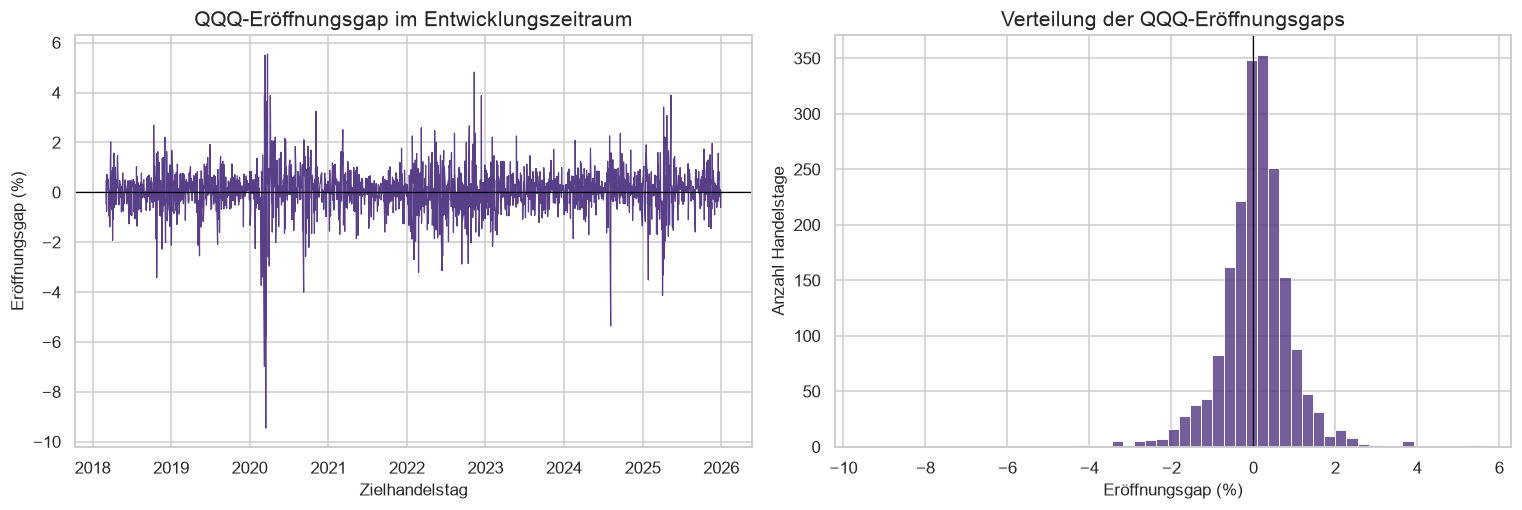

In [11]:
# Restrict every exploratory result to the development period
development_data = modeling_data[
    modeling_data["target_session_date"] < HOLDOUT_START
].copy()
assert development_data["target_session_date"].max() < HOLDOUT_START

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].plot(
    development_data["target_session_date"],
    development_data["qqq_gap_percent"],
    color=COLORS["qqq"],
    linewidth=0.8,
    alpha=0.9,
)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("QQQ-Eröffnungsgap im Entwicklungszeitraum")
axes[0].set_xlabel("Zielhandelstag")
axes[0].set_ylabel("Eröffnungsgap (%)")

sns.histplot(
    data=development_data,
    x="qqq_gap_percent",
    bins=55,
    color=COLORS["qqq"],
    ax=axes[1],
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Verteilung der QQQ-Eröffnungsgaps")
axes[1].set_xlabel("Eröffnungsgap (%)")
axes[1].set_ylabel("Anzahl Handelstage")

fig.tight_layout()
plt.show()

In [12]:
# Quantify target location, tails and class balance
mean_gap = development_data["qqq_gap_percent"].mean()
median_gap = development_data["qqq_gap_percent"].median()
positive_share = development_data[CLASSIFICATION_TARGET].mean()
absolute_gap_95 = development_data["qqq_gap_percent"].abs().quantile(0.95)

display(
    Markdown(
        f'''
### Interpretation

Der mittlere QQQ-Eröffnungsgap beträgt **{mean_gap:.3f}%**, der Median
**{median_gap:.3f}%**. In **{positive_share:.1%}** der
Entwicklungsbeobachtungen eröffnet QQQ höher als am vorherigen
Schluss. 95% der absoluten Gaps liegen unter **{absolute_gap_95:.2f}%**.
Einzelne starke Ausschläge und die Klassenverteilung müssen bei der
späteren Bewertung berücksichtigt werden; Accuracy wird deshalb gegen
eine historische Mehrheitsbaseline und zusätzlich mit Balanced
Accuracy beurteilt.
        '''
    )
)


### Interpretation

Der mittlere QQQ-Eröffnungsgap beträgt **0.049%**, der Median
**0.089%**. In **56.5%** der
Entwicklungsbeobachtungen eröffnet QQQ höher als am vorherigen
Schluss. 95% der absoluten Gaps liegen unter **1.77%**.
Einzelne starke Ausschläge und die Klassenverteilung müssen bei der
späteren Bewertung berücksichtigt werden; Accuracy wird deshalb gegen
eine historische Mehrheitsbaseline und zusätzlich mit Balanced
Accuracy beurteilt.
        

### 7.1 Richtung und Fensterlänge nach Wochentag

Wir prüfen, ob die positive Gap-Rate und die Dauer des
Informationsfensters systematisch mit dem Ziel-Wochentag variieren.
Montage enthalten in der Regel das gesamte Wochenende; Feiertage und
verkürzte Sitzungen können zusätzliche längere Fenster erzeugen.

,Beobachtungen,Positive_Rate,Median_Fensterstunden,Max_Fensterstunden
target_weekday,,,,
Montag,362,0.561,65.0,92.0
Dienstag,403,0.561,17.0,89.0
Mittwoch,396,0.596,17.0,44.0
Donnerstag,392,0.561,17.0,44.0
Freitag,392,0.546,17.0,44.0


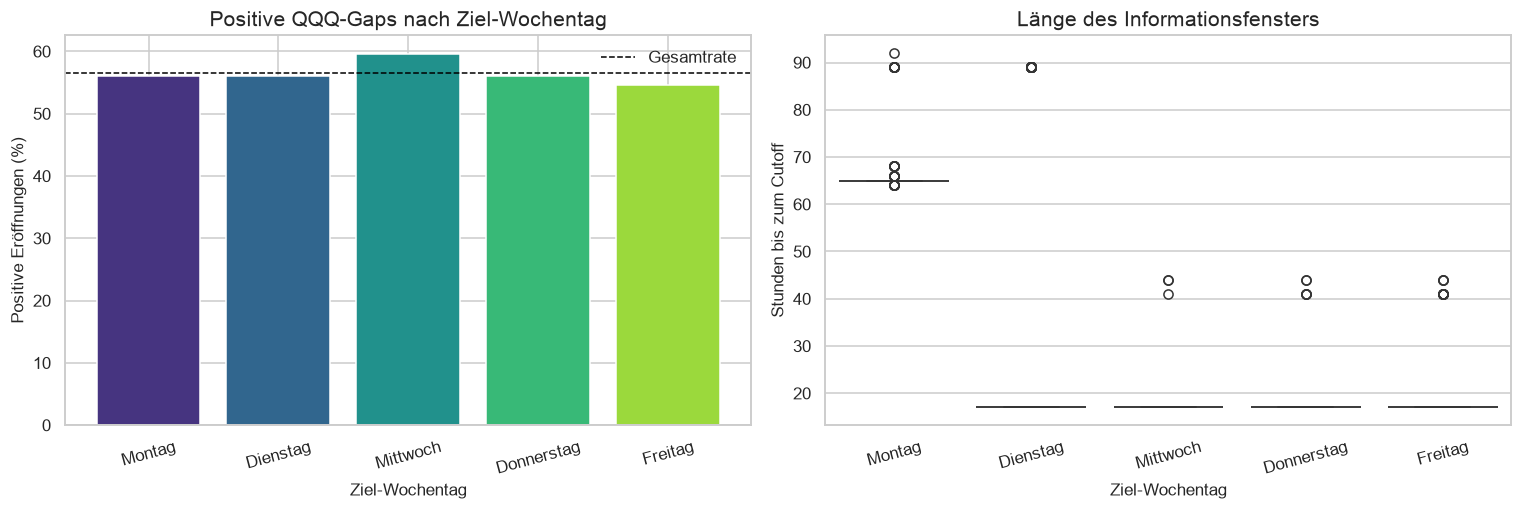

In [13]:
weekday_order = ["Montag", "Dienstag", "Mittwoch", "Donnerstag", "Freitag"]
weekday_summary = (
    development_data.groupby("target_weekday", observed=False)
    .agg(
        Beobachtungen=(CLASSIFICATION_TARGET, "size"),
        Positive_Rate=(CLASSIFICATION_TARGET, "mean"),
        Median_Fensterstunden=("overnight_hours", "median"),
        Max_Fensterstunden=("overnight_hours", "max"),
    )
    .reindex(weekday_order)
)
display(weekday_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
viridis_weekdays = [VIRIDIS(value) for value in np.linspace(0.15, 0.85, 5)]

axes[0].bar(
    weekday_summary.index,
    100 * weekday_summary["Positive_Rate"],
    color=viridis_weekdays,
)
axes[0].axhline(
    100 * positive_share,
    color="black",
    linewidth=1,
    linestyle="--",
    label="Gesamtrate",
)
axes[0].set_title("Positive QQQ-Gaps nach Ziel-Wochentag")
axes[0].set_xlabel("Ziel-Wochentag")
axes[0].set_ylabel("Positive Eröffnungen (%)")
axes[0].legend()

sns.boxplot(
    data=development_data,
    x="target_weekday",
    y="overnight_hours",
    order=weekday_order,
    hue="target_weekday",
    palette="viridis",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Länge des Informationsfensters")
axes[1].set_xlabel("Ziel-Wochentag")
axes[1].set_ylabel("Stunden bis zum Cutoff")

for axis in axes:
    axis.tick_params(axis="x", rotation=15)

fig.tight_layout()
plt.show()

In [14]:
# Describe observed weekday differences without causal interpretation
highest_weekday = weekday_summary["Positive_Rate"].idxmax()
lowest_weekday = weekday_summary["Positive_Rate"].idxmin()
monday_median_hours = weekday_summary.loc["Montag", "Median_Fensterstunden"]
weekday_median_hours = weekday_summary.loc[
    ["Dienstag", "Mittwoch", "Donnerstag", "Freitag"],
    "Median_Fensterstunden",
].median()

display(
    Markdown(
        f'''
### Interpretation

Die höchste positive Gap-Rate zeigt **{highest_weekday}**, die tiefste
**{lowest_weekday}**. Das mediane Montagsfenster umfasst
**{monday_median_hours:.0f} Stunden**, gegenüber
**{weekday_median_hours:.0f} Stunden** an den übrigen Handelstagen.
Diese Kalenderunterschiede rechtfertigen den Montag-Indikator und die
Fensterlänge im Kontrollmodell. Sie sind keine Evidenz für einen
Bitcoin-Effekt.
        '''
    )
)


### Interpretation

Die höchste positive Gap-Rate zeigt **Mittwoch**, die tiefste
**Freitag**. Das mediane Montagsfenster umfasst
**65 Stunden**, gegenüber
**17 Stunden** an den übrigen Handelstagen.
Diese Kalenderunterschiede rechtfertigen den Montag-Indikator und die
Fensterlänge im Kontrollmodell. Sie sind keine Evidenz für einen
Bitcoin-Effekt.
        

### 7.2 BTC-Overnight-Return und QQQ-Gap

Der Scatterplot zeigt den direkten linearen Zusammenhang. Fear & Greed
dient als Farbdimension, um mögliche Sentimentregime sichtbar zu
machen. Danach vergleichen wir alle Tage, Montage und die übrigen
Handelstage getrennt.

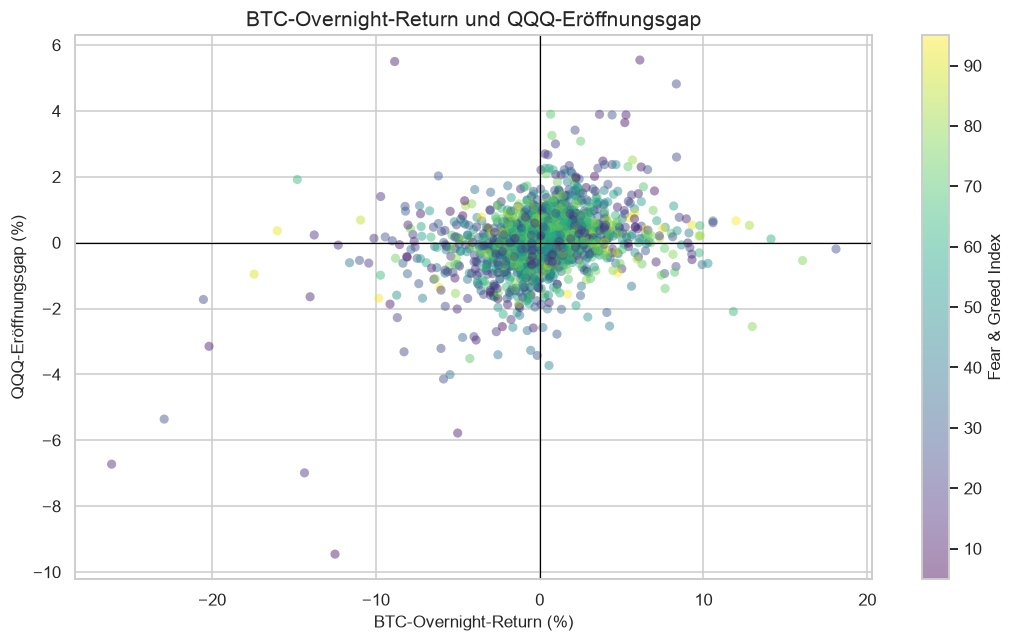

In [15]:
# Plot the direct relationship without fitting a predictive model
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    100 * development_data["btc_overnight_return"],
    development_data["qqq_gap_percent"],
    c=development_data["fear_greed"],
    cmap="viridis",
    alpha=0.45,
    edgecolor="none",
)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("BTC-Overnight-Return und QQQ-Eröffnungsgap")
plt.xlabel("BTC-Overnight-Return (%)")
plt.ylabel("QQQ-Eröffnungsgap (%)")
colorbar = plt.colorbar(scatter)
colorbar.set_label("Fear & Greed Index")
plt.tight_layout()
plt.show()

In [16]:
# Compare correlations overall and by the main calendar regime
monday_data = development_data[development_data["target_is_monday"] == 1]
other_days_data = development_data[development_data["target_is_monday"] == 0]

def target_correlation(frame):
    # Return the linear BTC-return relationship for one subset
    return frame[["btc_overnight_return", NUMERIC_TARGET]].corr().iloc[0, 1]


correlation_by_period = pd.DataFrame(
    {
        "Teilmenge": ["Alle Handelstage", "Montage", "Dienstag bis Freitag"],
        "Beobachtungen": [
            len(development_data),
            len(monday_data),
            len(other_days_data),
        ],
        "Korrelation": [
            target_correlation(development_data),
            target_correlation(monday_data),
            target_correlation(other_days_data),
        ],
    }
)
display(correlation_by_period.round(3))

overall_correlation = correlation_by_period.loc[0, "Korrelation"]
monday_correlation = correlation_by_period.loc[1, "Korrelation"]
other_days_correlation = correlation_by_period.loc[2, "Korrelation"]

display(
    Markdown(
        f'''
### Interpretation

Im gesamten Entwicklungszeitraum beträgt die lineare Korrelation
zwischen BTC-Overnight-Return und numerischem QQQ-Gap
**{overall_correlation:.3f}**. Für Montage liegt sie bei
**{monday_correlation:.3f}**, für Dienstag bis Freitag bei
**{other_days_correlation:.3f}**. Die grössere Stichprobe erlaubt damit
eine getrennte Beschreibung längerer und normaler Fenster. Ob die
Beziehung gegenüber Kontrollmerkmalen stabilen Zusatznutzen besitzt,
muss die spätere Walk-forward-Validierung zeigen.
        '''
    )
)

,Teilmenge,Beobachtungen,Korrelation
0,Alle Handelstage,1945,0.316
1,Montage,362,0.345
2,Dienstag bis Freitag,1583,0.306



### Interpretation

Im gesamten Entwicklungszeitraum beträgt die lineare Korrelation
zwischen BTC-Overnight-Return und numerischem QQQ-Gap
**0.316**. Für Montage liegt sie bei
**0.345**, für Dienstag bis Freitag bei
**0.306**. Die grössere Stichprobe erlaubt damit
eine getrennte Beschreibung längerer und normaler Fenster. Ob die
Beziehung gegenüber Kontrollmerkmalen stabilen Zusatznutzen besitzt,
muss die spätere Walk-forward-Validierung zeigen.
        

### 7.3 Richtungsanteil nach BTC-Return-Quintil

Eine reine Korrelation kann nichtlineare oder schwellenartige
Beziehungen übersehen. Deshalb teilen wir die BTC-Overnight-Returns im
Entwicklungszeitraum in fünf gleich grosse Gruppen und berechnen je
Gruppe den Anteil positiver QQQ-Gaps. Die Quintile werden nur für diese
deskriptive EDA verwendet und nicht als nachträglich ausgewählte
Modellfeatures übernommen.

,Beobachtungen,BTC_Return_Median,Positive_QQQ_Rate,QQQ_Gap_Median
btc_return_quintile,,,,
Q1 tief,389,-0.0289,0.3728,-0.1816
Q2,389,-0.0085,0.4910,-0.0118
Q3,389,0.0012,0.6015,0.1125
Q4,389,0.0115,0.6530,0.1888
Q5 hoch,389,0.0338,0.7069,0.2995


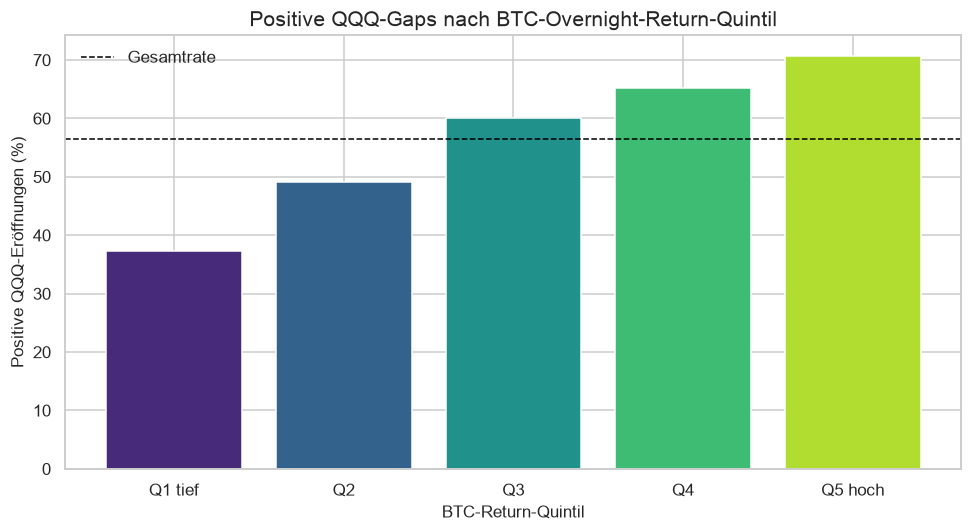

In [17]:
# Create equal-frequency bins for a descriptive monotonicity check
quintile_labels = ["Q1 tief", "Q2", "Q3", "Q4", "Q5 hoch"]
development_data["btc_return_quintile"] = pd.qcut(
    development_data["btc_overnight_return"],
    q=5,
    labels=quintile_labels,
)
quintile_summary = (
    development_data.groupby("btc_return_quintile", observed=False)
    .agg(
        Beobachtungen=(CLASSIFICATION_TARGET, "size"),
        BTC_Return_Median=("btc_overnight_return", "median"),
        Positive_QQQ_Rate=(CLASSIFICATION_TARGET, "mean"),
        QQQ_Gap_Median=("qqq_gap_percent", "median"),
    )
)
display(quintile_summary.round(4))

plt.figure(figsize=(9, 5))
plt.bar(
    quintile_summary.index.astype(str),
    100 * quintile_summary["Positive_QQQ_Rate"],
    color=[VIRIDIS(value) for value in np.linspace(0.12, 0.88, 5)],
)
plt.axhline(
    100 * positive_share,
    color="black",
    linewidth=1,
    linestyle="--",
    label="Gesamtrate",
)
plt.title("Positive QQQ-Gaps nach BTC-Overnight-Return-Quintil")
plt.xlabel("BTC-Return-Quintil")
plt.ylabel("Positive QQQ-Eröffnungen (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Summarize the observed range without selecting a threshold
lowest_quintile_rate = quintile_summary["Positive_QQQ_Rate"].iloc[0]
highest_quintile_rate = quintile_summary["Positive_QQQ_Rate"].iloc[-1]
quintile_rate_difference = highest_quintile_rate - lowest_quintile_rate
quintile_rates_are_ordered = quintile_summary[
    "Positive_QQQ_Rate"
].is_monotonic_increasing
quintile_pattern_text = (
    "Die positive QQQ-Rate steigt über alle fünf Quintile geordnet an."
    if quintile_rates_are_ordered
    else "Die positive QQQ-Rate verläuft über die fünf Quintile nicht geordnet."
)

display(
    Markdown(
        f'''
### Interpretation

Im tiefsten BTC-Return-Quintil sind **{lowest_quintile_rate:.1%}** der
QQQ-Gaps positiv, im höchsten Quintil **{highest_quintile_rate:.1%}**.
Die Differenz beträgt **{quintile_rate_difference:.1%}**.
{quintile_pattern_text} Das ist ein klarer deskriptiver Hinweis zugunsten
unserer Hypothese, bleibt aber eine In-Sample-Beschreibung und kein
Beleg für Out-of-sample-Prognosekraft. Die Quintile werden nicht als
nachträglich optimierte Schwellenwerte in die Modelle übernommen.
        '''
    )
)


### Interpretation

Im tiefsten BTC-Return-Quintil sind **37.3%** der
QQQ-Gaps positiv, im höchsten Quintil **70.7%**.
Die Differenz beträgt **33.4%**.
Die positive QQQ-Rate steigt über alle fünf Quintile geordnet an. Das ist ein klarer deskriptiver Hinweis zugunsten
unserer Hypothese, bleibt aber eine In-Sample-Beschreibung und kein
Beleg für Out-of-sample-Prognosekraft. Die Quintile werden nicht als
nachträglich optimierte Schwellenwerte in die Modelle übernommen.
        

### 7.4 Kompakte Korrelationsübersicht

Die Heatmap vergleicht den numerischen Gap mit einer kleinen, vorab
definierten Auswahl von Bitcoin-, Sentiment-, Makro- und
QQQ-Merkmalen. Sie dient der Plausibilitätsprüfung, nicht der
automatischen Feature-Auswahl.

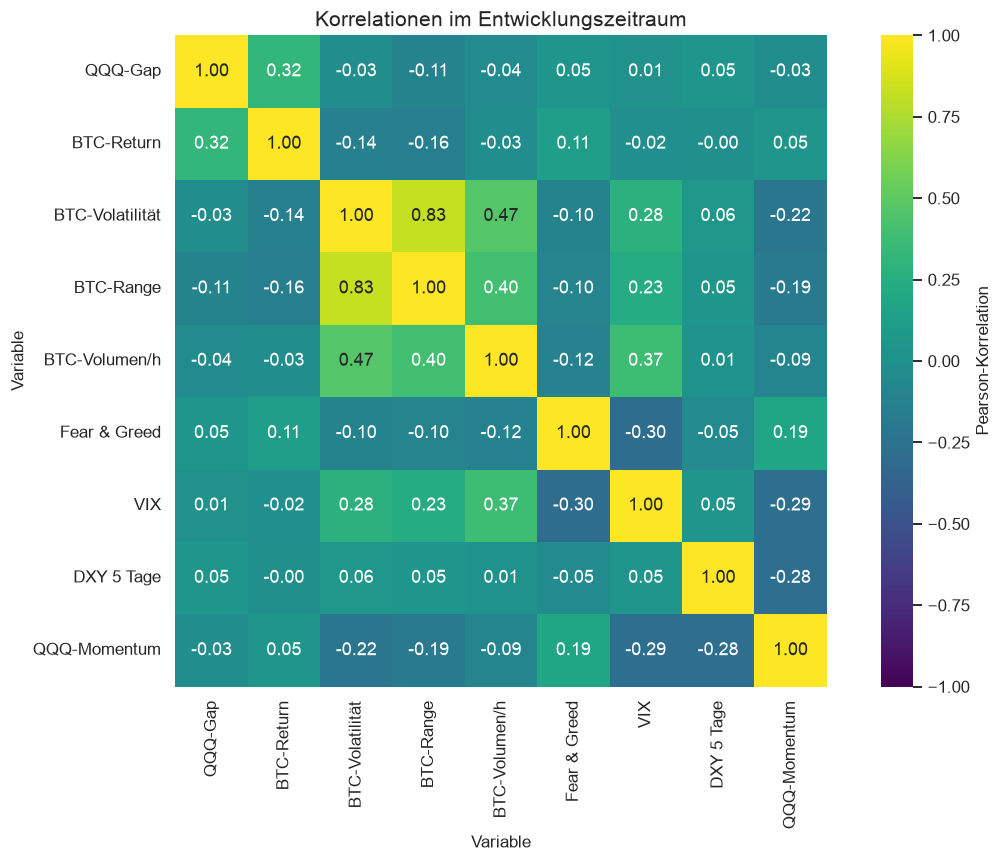

In [19]:
# Keep the heatmap focused on the research question
correlation_columns = [
    NUMERIC_TARGET,
    "btc_overnight_return",
    "btc_overnight_rv_intensity",
    "btc_overnight_range",
    "btc_overnight_log_volume_per_hour",
    "fear_greed",
    "vix_close",
    "dxy_change_5d",
    "qqq_momentum_5d",
]
correlation_labels = {
    NUMERIC_TARGET: "QQQ-Gap",
    "btc_overnight_return": "BTC-Return",
    "btc_overnight_rv_intensity": "BTC-Volatilität",
    "btc_overnight_range": "BTC-Range",
    "btc_overnight_log_volume_per_hour": "BTC-Volumen/h",
    "fear_greed": "Fear & Greed",
    "vix_close": "VIX",
    "dxy_change_5d": "DXY 5 Tage",
    "qqq_momentum_5d": "QQQ-Momentum",
}
correlation_matrix = development_data[correlation_columns].corr().rename(
    index=correlation_labels, columns=correlation_labels
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Pearson-Korrelation"},
)
plt.title("Korrelationen im Entwicklungszeitraum")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

In [20]:
# Rank target correlations for a concise evidence-based interpretation
target_correlations = (
    development_data[correlation_columns]
    .corr()[NUMERIC_TARGET]
    .drop(NUMERIC_TARGET)
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
strongest_feature = target_correlations.index[0]
strongest_value = target_correlations.iloc[0]

display(target_correlations.rename("Korrelation mit QQQ-Gap").round(3).to_frame())
display(
    Markdown(
        f'''
### Interpretation

Die stärkste absolute lineare Zielkorrelation in dieser bewusst kleinen
Auswahl besitzt **`{strongest_feature}`** mit
**{strongest_value:.3f}**. Die Grössenordnung ist eine
In-Sample-Beschreibung. Stark korrelierte Features können redundant
sein; schwach korrelierte Features können in nichtlinearen Modellen
gemeinsam nützlich werden. Deshalb bleiben die Feature-Sets wie vorab
definiert bestehen.
        '''
    )
)

,Korrelation mit QQQ-Gap
btc_overnight_return,0.316
btc_overnight_range,-0.108
dxy_change_5d,0.052
fear_greed,0.051
btc_overnight_log_volume_per_hour,-0.041
qqq_momentum_5d,-0.029
btc_overnight_rv_intensity,-0.029
vix_close,0.008



### Interpretation

Die stärkste absolute lineare Zielkorrelation in dieser bewusst kleinen
Auswahl besitzt **`btc_overnight_return`** mit
**0.316**. Die Grössenordnung ist eine
In-Sample-Beschreibung. Stark korrelierte Features können redundant
sein; schwach korrelierte Features können in nichtlinearen Modellen
gemeinsam nützlich werden. Deshalb bleiben die Feature-Sets wie vorab
definiert bestehen.
        

## 8. Expanding-window-Validierung und Mehrheitsbaseline

### 8.1 Jährliche Expanding-window-Folds

### Erklärung

Ein zufälliger Split würde zukünftige Marktregime in das Training
mischen. Wir verwenden deshalb fünf chronologische Folds. Für das
Validierungsjahr (v) besteht das Training aus allen Beobachtungen vor
dem 1. Januar von (v):

$$
\mathcal{T}_v = \{(x_t,y_t): date_t < 1.\ Januar\ v\},
\qquad
\mathcal{V}_v = \{(x_t,y_t): year(date_t)=v\}.
$$

Innerhalb eines Validierungsjahres darf eine Walk-forward-Methode nach
jedem beobachteten Zieltag auch diese neue Vergangenheit verwenden. Der
Holdout ab 2026 bleibt vollständig ausserhalb aller Folds.

In [21]:
# Define annual folds using development data only
fold_rows = []
for validation_year in VALIDATION_YEARS:
    validation_start = pd.Timestamp(f"{validation_year}-01-01")
    validation_end = pd.Timestamp(f"{validation_year + 1}-01-01")
    training_fold = development_data[
        development_data["target_session_date"] < validation_start
    ]
    validation_fold = development_data[
        (development_data["target_session_date"] >= validation_start)
        & (development_data["target_session_date"] < validation_end)
    ]

    # Enforce strict chronology and non-empty annual folds
    assert not training_fold.empty
    assert not validation_fold.empty
    assert (
        training_fold["target_session_date"].max()
        < validation_fold["target_session_date"].min()
    )
    assert validation_fold["target_session_date"].max() < HOLDOUT_START

    fold_rows.append(
        {
            "Validierungsjahr": validation_year,
            "Training von": training_fold["target_session_date"].min(),
            "Training bis": training_fold["target_session_date"].max(),
            "Training Beobachtungen": len(training_fold),
            "Training Positivrate": training_fold[
                CLASSIFICATION_TARGET
            ].mean(),
            "Validierung von": validation_fold[
                "target_session_date"
            ].min(),
            "Validierung bis": validation_fold[
                "target_session_date"
            ].max(),
            "Validierung Beobachtungen": len(validation_fold),
        }
    )

fold_summary = pd.DataFrame(fold_rows)
assert fold_summary["Validierung Beobachtungen"].sum() == 1248
display(fold_summary.round({"Training Positivrate": 3}))

,Validierungsjahr,Training von,Training bis,Training Beobachtungen,Training Positivrate,Validierung von,Validierung bis,Validierung Beobachtungen
0,2021,2018-03-05,2020-12-31,697,0.590,2021-01-04,2021-12-31,246
1,2022,2018-03-05,2021-12-31,943,0.587,2022-01-03,2022-12-30,251
2,2023,2018-03-05,2022-12-30,1194,0.559,2023-01-03,2023-12-29,249
3,2024,2018-03-05,2023-12-29,1443,0.554,2024-01-02,2024-12-31,252
4,2025,2018-03-05,2024-12-31,1695,0.560,2025-01-02,2025-12-31,250


In [22]:
# Summarize the executed fold boundaries
first_training_size = int(fold_summary.iloc[0]["Training Beobachtungen"])
last_training_size = int(fold_summary.iloc[-1]["Training Beobachtungen"])
validation_forecasts = int(
    fold_summary["Validierung Beobachtungen"].sum()
)

display(
    Markdown(
        f'''
### Interpretation

Der erste Fold trainiert auf **{first_training_size} Handelstagen** aus
2018 bis 2020 und validiert auf 2021. Bis zum letzten Fold wächst das
Starttraining auf **{last_training_size} Beobachtungen**. Insgesamt
enthalten die fünf Validierungsjahre **{validation_forecasts}
chronologische Prognosetermine**. Jede Trainingsperiode endet strikt
vor ihrer Validierung; Daten ab 2026 werden nicht verwendet.
        '''
    )
)


### Interpretation

Der erste Fold trainiert auf **697 Handelstagen** aus
2018 bis 2020 und validiert auf 2021. Bis zum letzten Fold wächst das
Starttraining auf **1695 Beobachtungen**. Insgesamt
enthalten die fünf Validierungsjahre **1248
chronologische Prognosetermine**. Jede Trainingsperiode endet strikt
vor ihrer Validierung; Daten ab 2026 werden nicht verwendet.
        

### 8.2 Historische Mehrheitsklasse

### Erklärung

Die naive Baseline verwendet keine Features. Vor jedem Prognosetag
(t) berechnen wir den Anteil positiver QQQ-Gaps in allen bereits
beobachteten Zielwerten:

$$
\hat p_t = \frac{1}{N_t}\sum_{i:date_i<date_t} Direction_i,
\qquad
\widehat{Direction}_t = \mathbb{1}(\hat p_t \ge 0.5).
$$

Bei einem exakten Gleichstand wählen wir die positive Klasse. Die
Baseline wird vor jedem Handelstag aktualisiert und ist damit strenger
als eine einmal auf dem gesamten Entwicklungszeitraum bestimmte
Mehrheitsklasse.

Wir berichten Accuracy und Balanced Accuracy:

$$
Balanced\ Accuracy = \frac{1}{2}(TPR + TNR).
$$

Balanced Accuracy zeigt, ob ein Modell beide Richtungen erkennt, statt
nur von der häufigeren Klasse zu profitieren.

In [23]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Generate one strictly historical majority forecast per validation day
majority_rows = []
for validation_year in VALIDATION_YEARS:
    validation_fold = development_data[
        development_data["target_session_date"].dt.year
        == validation_year
    ]

    for observation in validation_fold.itertuples(index=False):
        training_history = development_data[
            development_data["target_session_date"]
            < observation.target_session_date
        ]
        historical_positive_rate = training_history[
            CLASSIFICATION_TARGET
        ].mean()

        majority_rows.append(
            {
                "model": "Historische Mehrheitsklasse",
                "fold_year": validation_year,
                "forecast_date": observation.target_session_date,
                "train_start": training_history[
                    "target_session_date"
                ].min(),
                "train_end": training_history[
                    "target_session_date"
                ].max(),
                "train_size": len(training_history),
                "historical_positive_rate": historical_positive_rate,
                "prediction": int(historical_positive_rate >= 0.5),
                "actual": observation.qqq_gap_direction,
                "target_is_monday": observation.target_is_monday,
            }
        )

majority_predictions = pd.DataFrame(majority_rows).sort_values(
    "forecast_date"
).reset_index(drop=True)

# Validate the expanding handoff and protect the holdout
assert len(majority_predictions) == 1248
assert majority_predictions["forecast_date"].is_monotonic_increasing
assert majority_predictions["forecast_date"].is_unique
assert (
    majority_predictions["train_end"]
    < majority_predictions["forecast_date"]
).all()
assert (majority_predictions["forecast_date"] < HOLDOUT_START).all()
assert majority_predictions["prediction"].isin([0, 1]).all()
assert majority_predictions["actual"].isin([0, 1]).all()

# Save the transparent forecast-level audit trail
majority_output_path = (
    PROCESSED_DATA_DIR / "btc_overnight_qqq_majority_baseline.csv"
)
majority_predictions.to_csv(majority_output_path, index=False)

majority_head = majority_predictions.head(6).copy()
majority_tail = majority_predictions.tail(3).copy()
for preview in [majority_head, majority_tail]:
    numeric_columns = preview.select_dtypes(include="number").columns
    preview[numeric_columns] = preview[numeric_columns].round(3)
    display(preview)

,model,fold_year,forecast_date,train_start,train_end,train_size,historical_positive_rate,prediction,actual,target_is_monday
0,Historische Mehrheitsklasse,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,1,1,1
1,Historische Mehrheitsklasse,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,1,0,0
2,Historische Mehrheitsklasse,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,1,0,0
3,Historische Mehrheitsklasse,2021,2021-01-07,2018-03-05,2021-01-06,700,0.589,1,1,0
4,Historische Mehrheitsklasse,2021,2021-01-08,2018-03-05,2021-01-07,701,0.589,1,1,0
5,Historische Mehrheitsklasse,2021,2021-01-11,2018-03-05,2021-01-08,702,0.590,1,0,1


,model,fold_year,forecast_date,train_start,train_end,train_size,historical_positive_rate,prediction,actual,target_is_monday
1245,Historische Mehrheitsklasse,2025,2025-12-29,2018-03-05,2025-12-26,1942,0.565,1,0,1
1246,Historische Mehrheitsklasse,2025,2025-12-30,2018-03-05,2025-12-29,1943,0.565,1,0,0
1247,Historische Mehrheitsklasse,2025,2025-12-31,2018-03-05,2025-12-30,1944,0.565,1,1,0


,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
Alle Handelstage,1248.0,0.551,1.0,0.551,0.5
Montage,231.0,0.558,1.0,0.558,0.5
Dienstag bis Freitag,1017.0,0.550,1.0,0.550,0.5


,Validierungsjahr,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,2021,246.0,0.581,1.0,0.581,0.5
1,2022,251.0,0.454,1.0,0.454,0.5
2,2023,249.0,0.526,1.0,0.526,0.5
3,2024,252.0,0.599,1.0,0.599,0.5
4,2025,250.0,0.596,1.0,0.596,0.5


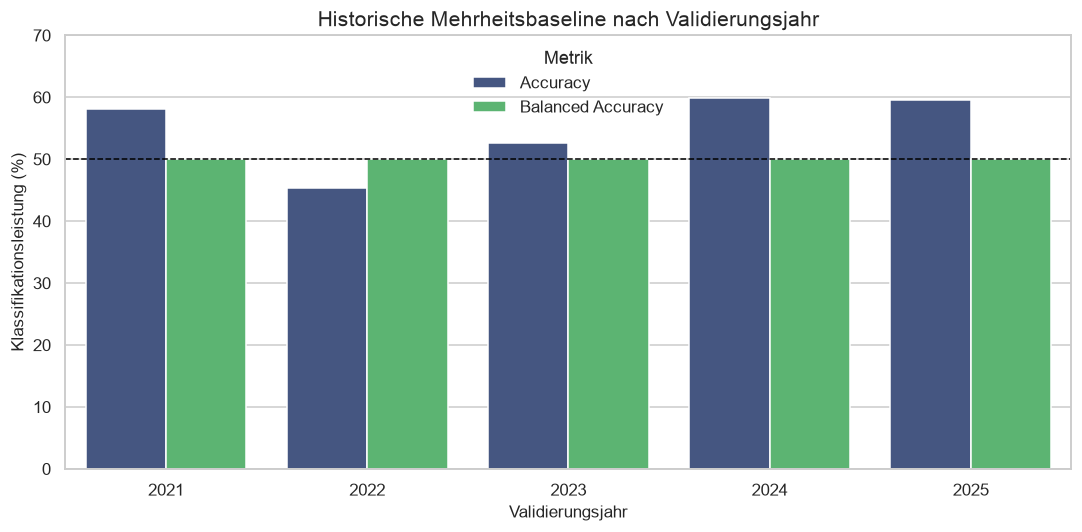

In [24]:
def summarize_classification(frame):
    # Calculate the two agreed classification metrics
    return pd.Series(
        {
            "Beobachtungen": len(frame),
            "Positivrate Ziel": frame["actual"].mean(),
            "Positivrate Prognose": frame["prediction"].mean(),
            "Accuracy": accuracy_score(
                frame["actual"], frame["prediction"]
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                frame["actual"], frame["prediction"]
            ),
        }
    )


# Report overall and calendar-subgroup results
baseline_scope_metrics = pd.DataFrame(
    {
        "Alle Handelstage": summarize_classification(
            majority_predictions
        ),
        "Montage": summarize_classification(
            majority_predictions[
                majority_predictions["target_is_monday"] == 1
            ]
        ),
        "Dienstag bis Freitag": summarize_classification(
            majority_predictions[
                majority_predictions["target_is_monday"] == 0
            ]
        ),
    }
).T

baseline_year_metrics = (
    majority_predictions.groupby("fold_year", observed=False)
    .apply(summarize_classification, include_groups=False)
    .reset_index()
    .rename(columns={"fold_year": "Validierungsjahr"})
)

display(baseline_scope_metrics.round(3))
display(baseline_year_metrics.round(3))

# Visualize annual performance on a common percentage scale
plot_metrics = baseline_year_metrics.melt(
    id_vars="Validierungsjahr",
    value_vars=["Accuracy", "Balanced Accuracy"],
    var_name="Metrik",
    value_name="Wert",
)
plot_metrics["Wert (%)"] = 100 * plot_metrics["Wert"]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_metrics,
    x="Validierungsjahr",
    y="Wert (%)",
    hue="Metrik",
    palette=[VIRIDIS(0.25), VIRIDIS(0.72)],
)
plt.axhline(50, color="black", linewidth=1, linestyle="--")
plt.ylim(0, 70)
plt.title("Historische Mehrheitsbaseline nach Validierungsjahr")
plt.xlabel("Validierungsjahr")
plt.ylabel("Klassifikationsleistung (%)")
plt.legend(title="Metrik")
plt.tight_layout()
plt.show()

In [25]:
# Interpret the executed baseline without overstating skill
overall_accuracy = baseline_scope_metrics.loc[
    "Alle Handelstage", "Accuracy"
]
overall_balanced_accuracy = baseline_scope_metrics.loc[
    "Alle Handelstage", "Balanced Accuracy"
]
predicted_positive_count = int(majority_predictions["prediction"].sum())
best_year_row = baseline_year_metrics.loc[
    baseline_year_metrics["Accuracy"].idxmax()
]
worst_year_row = baseline_year_metrics.loc[
    baseline_year_metrics["Accuracy"].idxmin()
]

display(
    Markdown(
        f'''
### Interpretation

Die historische Positivrate bleibt an allen Prognoseterminen über 50%.
Deshalb sagt die Baseline für **{predicted_positive_count} von
{len(majority_predictions)} Terminen** eine positive Eröffnung voraus.
Ihre gesamte Accuracy beträgt **{overall_accuracy:.1%}**, die Balanced
Accuracy erwartungsgemäss **{overall_balanced_accuracy:.1%}**. Die
höhere Accuracy entsteht ausschliesslich aus der leicht häufigeren
positiven Klasse; die Baseline erkennt keine negativen Gaps.

Die jährliche Accuracy schwankt von
**{worst_year_row['Accuracy']:.1%} im Jahr
{int(worst_year_row['Validierungsjahr'])}** bis
**{best_year_row['Accuracy']:.1%} im Jahr
{int(best_year_row['Validierungsjahr'])}**. Diese Baseline ist damit die
Mindesthürde: Ein nützliches Richtungsmodell sollte nicht nur ihre
Accuracy übertreffen, sondern auch eine Balanced Accuracy klar über
50% erreichen.
        '''
    )
)


### Interpretation

Die historische Positivrate bleibt an allen Prognoseterminen über 50%.
Deshalb sagt die Baseline für **1248 von
1248 Terminen** eine positive Eröffnung voraus.
Ihre gesamte Accuracy beträgt **55.1%**, die Balanced
Accuracy erwartungsgemäss **50.0%**. Die
höhere Accuracy entsteht ausschliesslich aus der leicht häufigeren
positiven Klasse; die Baseline erkennt keine negativen Gaps.

Die jährliche Accuracy schwankt von
**45.4% im Jahr
2022** bis
**59.9% im Jahr
2024**. Diese Baseline ist damit die
Mindesthürde: Ein nützliches Richtungsmodell sollte nicht nur ihre
Accuracy übertreffen, sondern auch eine Balanced Accuracy klar über
50% erreichen.
        

## 9. Logistische Regression

### 9.1 Methode und Walk-forward-Training

### Erklärung

Die logistische Regression modelliert direkt die Wahrscheinlichkeit
eines positiven QQQ-Gaps. Für standardisierte Features (z_{t,j})
gilt:

$$
P(Direction_t=1\mid z_t)
= \sigma\left(\beta_0 + \sum_{j=1}^{p}\beta_j z_{t,j}\right),
\qquad
\sigma(a)=\frac{1}{1+e^{-a}}.
$$

Die Standardisierung wird vor jedem Prognosetag ausschliesslich auf der
damaligen Trainingshistorie geschätzt:

$$
z_{t,j}=\frac{x_{t,j}-\mu_{j,train}}{s_{j,train}}.
$$

Wir verwenden eine L2-Regularisierung mit festem (C=1). Weil die EDA
eine leichte Klassenverschiebung zeigt, berechnet
`class_weight="balanced"` in jedem Trainingsfenster Gewichte aus den
dort verfügbaren Zielwerten. Dadurch erhalten positive und negative
Beobachtungen im Fit dasselbe Gesamtgewicht.

Wir vergleichen zwei vorab definierte Varianten:

1. **Logistische Regression Kontrolle:** QQQ, Fear & Greed, VIX, DXY,
   Montag-Indikator und Fensterlänge.
2. **Logistische Regression + Bitcoin:** dieselben Variablen plus die
   fünf BTC-Overnight-Merkmale.

Beide Modelle werden vor jedem Validierungstag neu auf allen früheren
Beobachtungen geschätzt. Es gibt keine Hyperparametersuche und keinen
Zugriff auf den Holdout ab 2026.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LOGISTIC_MODEL_FEATURES = {
    "Logistische Regression Kontrolle": CONTROL_FEATURES,
    "Logistische Regression + Bitcoin": FULL_FEATURES,
}
LOGISTIC_PARAMETERS = {
    "C": 1.0,
    "solver": "lbfgs",
    "class_weight": "balanced",
    "max_iter": 2000,
    "random_state": RANDOM_SEED,
}

logistic_rows = []
for model_name, feature_columns in LOGISTIC_MODEL_FEATURES.items():
    for validation_year in VALIDATION_YEARS:
        validation_fold = development_data[
            development_data["target_session_date"].dt.year
            == validation_year
        ]

        for _, observation in validation_fold.iterrows():
            forecast_date = observation["target_session_date"]
            training_history = development_data[
                development_data["target_session_date"] < forecast_date
            ]

            # Fit scaling and classification only on historical rows
            classifier = make_pipeline(
                StandardScaler(),
                LogisticRegression(**LOGISTIC_PARAMETERS),
            )
            classifier.fit(
                training_history[feature_columns],
                training_history[CLASSIFICATION_TARGET],
            )

            forecast_features = (
                observation[feature_columns].to_frame().T.astype(float)
            )
            positive_probability = classifier.predict_proba(
                forecast_features
            )[0, 1]
            prediction = int(positive_probability >= 0.5)
            fitted_logistic = classifier.named_steps[
                "logisticregression"
            ]

            logistic_rows.append(
                {
                    "model": model_name,
                    "fold_year": validation_year,
                    "forecast_date": forecast_date,
                    "train_start": training_history[
                        "target_session_date"
                    ].min(),
                    "train_end": training_history[
                        "target_session_date"
                    ].max(),
                    "train_size": len(training_history),
                    "train_positive_rate": training_history[
                        CLASSIFICATION_TARGET
                    ].mean(),
                    "positive_probability": positive_probability,
                    "prediction": prediction,
                    "actual": observation[CLASSIFICATION_TARGET],
                    "target_is_monday": observation["target_is_monday"],
                    "iterations": int(fitted_logistic.n_iter_.max()),
                }
            )

logistic_predictions = pd.DataFrame(logistic_rows).sort_values(
    ["model", "forecast_date"]
).reset_index(drop=True)

# Validate identical dates, chronology and numerical convergence
expected_forecast_dates = majority_predictions["forecast_date"].tolist()
for model_name in LOGISTIC_MODEL_FEATURES:
    model_predictions = logistic_predictions[
        logistic_predictions["model"] == model_name
    ]
    assert len(model_predictions) == len(majority_predictions)
    assert model_predictions["forecast_date"].tolist() == expected_forecast_dates
    assert model_predictions["actual"].tolist() == majority_predictions[
        "actual"
    ].tolist()
    assert (
        model_predictions["train_end"]
        < model_predictions["forecast_date"]
    ).all()

assert (logistic_predictions["forecast_date"] < HOLDOUT_START).all()
assert logistic_predictions["positive_probability"].between(0, 1).all()
assert logistic_predictions["prediction"].isin([0, 1]).all()
assert logistic_predictions["iterations"].max() < LOGISTIC_PARAMETERS[
    "max_iter"
]

# Save one transparent forecast-level audit trail for both variants
logistic_output_path = (
    PROCESSED_DATA_DIR / "btc_overnight_qqq_logistic_backtest.csv"
)
logistic_predictions.to_csv(logistic_output_path, index=False)

logistic_preview = logistic_predictions.groupby(
    "model", observed=False, sort=False
).head(3).copy()
logistic_numeric = logistic_preview.select_dtypes(include="number").columns
logistic_preview[logistic_numeric] = logistic_preview[
    logistic_numeric
].round(3)
display(logistic_preview)

,model,fold_year,forecast_date,train_start,train_end,train_size,train_positive_rate,positive_probability,prediction,actual,target_is_monday,iterations
0,Logistische Regression + Bitcoin,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,0.270,0,1,1,21
1,Logistische Regression + Bitcoin,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,0.437,0,0,0,22
2,Logistische Regression + Bitcoin,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,0.652,1,0,0,21
1248,Logistische Regression Kontrolle,2021,2021-01-04,2018-03-05,2020-12-31,697,0.590,0.388,0,1,1,13
1249,Logistische Regression Kontrolle,2021,2021-01-05,2018-03-05,2021-01-04,698,0.590,0.506,1,0,0,13
1250,Logistische Regression Kontrolle,2021,2021-01-06,2018-03-05,2021-01-05,699,0.589,0.630,1,0,0,13


In [27]:
# Confirm the shared expanding-window handoff
logistic_handoff = (
    logistic_predictions.groupby("model", observed=False, sort=False)
    .agg(
        Prognosen=("forecast_date", "size"),
        Erste_Prognose=("forecast_date", "min"),
        Letzte_Prognose=("forecast_date", "max"),
        Erstes_Training=("train_size", "min"),
        Letztes_Training=("train_size", "max"),
        Max_Iterationen=("iterations", "max"),
    )
    .reset_index()
)
display(logistic_handoff)

maximum_iterations = int(logistic_predictions["iterations"].max())
display(
    Markdown(
        f'''
### Interpretation

Beide Varianten erzeugen dieselben **{len(majority_predictions)}
Prognosetermine** wie die Mehrheitsbaseline. Das Training wächst vor
jedem Handelstag um den neu bekannten Zielwert. Die Fits benötigen
höchstens **{maximum_iterations} Optimierungsschritte** und bleiben
damit deutlich unter dem Limit von
**{LOGISTIC_PARAMETERS['max_iter']}**; es gibt keinen Hinweis auf ein
Konvergenzproblem.
        '''
    )
)

,model,Prognosen,Erste_Prognose,Letzte_Prognose,Erstes_Training,Letztes_Training,Max_Iterationen
0,Logistische Regression + Bitcoin,1248,2021-01-04,2025-12-31,697,1944,23
1,Logistische Regression Kontrolle,1248,2021-01-04,2025-12-31,697,1944,15



### Interpretation

Beide Varianten erzeugen dieselben **1248
Prognosetermine** wie die Mehrheitsbaseline. Das Training wächst vor
jedem Handelstag um den neu bekannten Zielwert. Die Fits benötigen
höchstens **23 Optimierungsschritte** und bleiben
damit deutlich unter dem Limit von
**2000**; es gibt keinen Hinweis auf ein
Konvergenzproblem.
        

### 9.2 Ergebnisse und Bitcoin-Zusatznutzen

### Erklärung

Wir vergleichen die beiden logistischen Varianten und die
Mehrheitsbaseline auf identischen 1’248 Prognoseterminen. Neben dem
Gesamtergebnis zeigen wir die Montagsgruppe sowie jedes
Validierungsjahr. Entscheidend für die Forschungsfrage ist der direkte
Unterschied zwischen Kontrolle und `+ Bitcoin`.

In [28]:
# Combine baseline and logistic predictions on the shared dates
comparison_predictions = pd.concat(
    [
        majority_predictions[
            [
                "model",
                "fold_year",
                "forecast_date",
                "prediction",
                "actual",
                "target_is_monday",
            ]
        ],
        logistic_predictions[
            [
                "model",
                "fold_year",
                "forecast_date",
                "prediction",
                "actual",
                "target_is_monday",
            ]
        ],
    ],
    ignore_index=True,
)

model_order = [
    "Historische Mehrheitsklasse",
    "Logistische Regression Kontrolle",
    "Logistische Regression + Bitcoin",
]

overall_model_metrics = (
    comparison_predictions.groupby("model", observed=False, sort=False)
    .apply(summarize_classification, include_groups=False)
    .reindex(model_order)
    .reset_index()
)

logistic_year_metrics = (
    logistic_predictions.groupby(
        ["model", "fold_year"], observed=False, sort=False
    )
    .apply(summarize_classification, include_groups=False)
    .reset_index()
    .rename(columns={"fold_year": "Validierungsjahr"})
)

scope_rows = []
for model_name in model_order:
    model_predictions = comparison_predictions[
        comparison_predictions["model"] == model_name
    ]
    for scope_name, scope_frame in [
        ("Alle Handelstage", model_predictions),
        (
            "Montage",
            model_predictions[model_predictions["target_is_monday"] == 1],
        ),
        (
            "Dienstag bis Freitag",
            model_predictions[model_predictions["target_is_monday"] == 0],
        ),
    ]:
        metrics = summarize_classification(scope_frame).to_dict()
        scope_rows.append(
            {"Modell": model_name, "Teilmenge": scope_name, **metrics}
        )

model_scope_metrics = pd.DataFrame(scope_rows)

display(overall_model_metrics.round(3))
display(logistic_year_metrics.round(3))
display(model_scope_metrics.round(3))

,model,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Historische Mehrheitsklasse,1248.0,0.551,1.000,0.551,0.500
1,Logistische Regression Kontrolle,1248.0,0.551,0.585,0.524,0.515
2,Logistische Regression + Bitcoin,1248.0,0.551,0.622,0.607,0.596


,model,Validierungsjahr,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Logistische Regression + Bitcoin,2021,246.0,0.581,0.646,0.553,0.530
1,Logistische Regression + Bitcoin,2022,251.0,0.454,0.430,0.633,0.628
2,Logistische Regression + Bitcoin,2023,249.0,0.526,0.558,0.534,0.531
3,Logistische Regression + Bitcoin,2024,252.0,0.599,0.706,0.631,0.594
4,Logistische Regression + Bitcoin,2025,250.0,0.596,0.768,0.684,0.638
5,Logistische Regression Kontrolle,2021,246.0,0.581,0.671,0.488,0.459
6,Logistische Regression Kontrolle,2022,251.0,0.454,0.458,0.526,0.522
7,Logistische Regression Kontrolle,2023,249.0,0.526,0.622,0.502,0.496
8,Logistische Regression Kontrolle,2024,252.0,0.599,0.611,0.504,0.481
9,Logistische Regression Kontrolle,2025,250.0,0.596,0.564,0.600,0.591


,Modell,Teilmenge,Beobachtungen,Positivrate Ziel,Positivrate Prognose,Accuracy,Balanced Accuracy
0,Historische Mehrheitsklasse,Alle Handelstage,1248.0,0.551,1.000,0.551,0.500
1,Historische Mehrheitsklasse,Montage,231.0,0.558,1.000,0.558,0.500
2,Historische Mehrheitsklasse,Dienstag bis Freitag,1017.0,0.550,1.000,0.550,0.500
3,Logistische Regression Kontrolle,Alle Handelstage,1248.0,0.551,0.585,0.524,0.515
4,Logistische Regression Kontrolle,Montage,231.0,0.558,0.429,0.437,0.445
5,Logistische Regression Kontrolle,Dienstag bis Freitag,1017.0,0.550,0.620,0.544,0.532
6,Logistische Regression + Bitcoin,Alle Handelstage,1248.0,0.551,0.622,0.607,0.596
7,Logistische Regression + Bitcoin,Montage,231.0,0.558,0.550,0.610,0.606
8,Logistische Regression + Bitcoin,Dienstag bis Freitag,1017.0,0.550,0.638,0.607,0.594


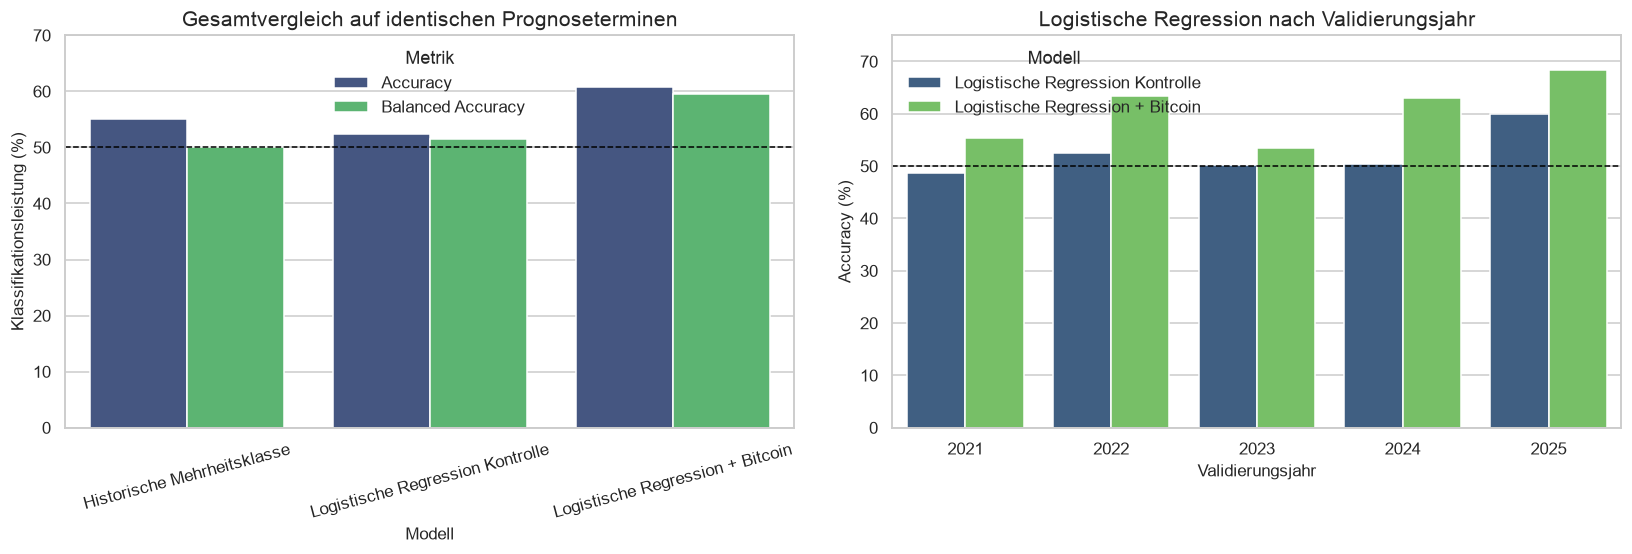

In [29]:
# Plot overall and annual metrics on a shared percentage scale
overall_plot = overall_model_metrics.melt(
    id_vars="model",
    value_vars=["Accuracy", "Balanced Accuracy"],
    var_name="Metrik",
    value_name="Wert",
)
overall_plot["Wert (%)"] = 100 * overall_plot["Wert"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.barplot(
    data=overall_plot,
    x="model",
    y="Wert (%)",
    hue="Metrik",
    order=model_order,
    palette=[VIRIDIS(0.25), VIRIDIS(0.72)],
    ax=axes[0],
)
axes[0].axhline(50, color="black", linewidth=1, linestyle="--")
axes[0].set_ylim(0, 70)
axes[0].set_title("Gesamtvergleich auf identischen Prognoseterminen")
axes[0].set_xlabel("Modell")
axes[0].set_ylabel("Klassifikationsleistung (%)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Metrik")

yearly_plot = logistic_year_metrics.copy()
yearly_plot["Accuracy (%)"] = 100 * yearly_plot["Accuracy"]
sns.barplot(
    data=yearly_plot,
    x="Validierungsjahr",
    y="Accuracy (%)",
    hue="model",
    hue_order=[
        "Logistische Regression Kontrolle",
        "Logistische Regression + Bitcoin",
    ],
    palette=[VIRIDIS(0.30), VIRIDIS(0.78)],
    ax=axes[1],
)
axes[1].axhline(50, color="black", linewidth=1, linestyle="--")
axes[1].set_ylim(0, 75)
axes[1].set_title("Logistische Regression nach Validierungsjahr")
axes[1].set_xlabel("Validierungsjahr")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(title="Modell")

fig.tight_layout()
plt.show()

In [30]:
# Derive the written comparison only from executed predictions
overall_by_model = overall_model_metrics.set_index("model")
control_accuracy = overall_by_model.loc[
    "Logistische Regression Kontrolle", "Accuracy"
]
bitcoin_accuracy = overall_by_model.loc[
    "Logistische Regression + Bitcoin", "Accuracy"
]
control_balanced = overall_by_model.loc[
    "Logistische Regression Kontrolle", "Balanced Accuracy"
]
bitcoin_balanced = overall_by_model.loc[
    "Logistische Regression + Bitcoin", "Balanced Accuracy"
]
bitcoin_predicted_positive_rate = overall_by_model.loc[
    "Logistische Regression + Bitcoin", "Positivrate Prognose"
]
scope_by_model = model_scope_metrics.set_index(["Modell", "Teilmenge"])
monday_control_accuracy = scope_by_model.loc[
    ("Logistische Regression Kontrolle", "Montage"), "Accuracy"
]
monday_bitcoin_accuracy = scope_by_model.loc[
    ("Logistische Regression + Bitcoin", "Montage"), "Accuracy"
]
monday_bitcoin_balanced = scope_by_model.loc[
    ("Logistische Regression + Bitcoin", "Montage"),
    "Balanced Accuracy",
]

yearly_pivot = logistic_year_metrics.pivot(
    index="Validierungsjahr", columns="model", values="Accuracy"
)
bitcoin_year_wins = int(
    (
        yearly_pivot["Logistische Regression + Bitcoin"]
        > yearly_pivot["Logistische Regression Kontrolle"]
    ).sum()
)

display(
    Markdown(
        f'''
### Interpretation

Die Kontrollvariante erreicht **{control_accuracy:.1%} Accuracy** und
**{control_balanced:.1%} Balanced Accuracy**. Mit den fünf
Bitcoin-Merkmalen steigen die Werte auf **{bitcoin_accuracy:.1%}** und
**{bitcoin_balanced:.1%}**. Der direkte Zusatz beträgt damit
**{bitcoin_accuracy - control_accuracy:.1%}-Punkte bei Accuracy** und
**{bitcoin_balanced - control_balanced:.1%}-Punkte bei Balanced
Accuracy**.

Die Bitcoin-Variante prognostiziert in
**{bitcoin_predicted_positive_rate:.1%}** der Fälle positiv und erkennt
somit beide Klassen. Sie übertrifft die Kontrollvariante in
**{bitcoin_year_wins} von {len(VALIDATION_YEARS)} Validierungsjahren**
bei der Accuracy. Das ist ein konsistenter Out-of-sample-Hinweis auf
zusätzlichen Informationsgehalt der BTC-Overnight-Merkmale innerhalb
der logistischen Regression.

An den **{int((majority_predictions['target_is_monday'] == 1).sum())}
Montagen** steigt die Accuracy von
**{monday_control_accuracy:.1%} ohne Bitcoin** auf
**{monday_bitcoin_accuracy:.1%} mit Bitcoin**; die Bitcoin-Variante
erreicht dort **{monday_bitcoin_balanced:.1%} Balanced Accuracy**. Die
längeren Wochenendfenster widersprechen dem Gesamtergebnis somit nicht.
Es ist dennoch kein finaler Beweis: Die Modellparameter sind bewusst
einfach, weitere Modellklassen fehlen, und der Holdout 2026 bleibt
unangetastet.
        '''
    )
)


### Interpretation

Die Kontrollvariante erreicht **52.4% Accuracy** und
**51.5% Balanced Accuracy**. Mit den fünf
Bitcoin-Merkmalen steigen die Werte auf **60.7%** und
**59.6%**. Der direkte Zusatz beträgt damit
**8.3%-Punkte bei Accuracy** und
**8.0%-Punkte bei Balanced
Accuracy**.

Die Bitcoin-Variante prognostiziert in
**62.2%** der Fälle positiv und erkennt
somit beide Klassen. Sie übertrifft die Kontrollvariante in
**5 von 5 Validierungsjahren**
bei der Accuracy. Das ist ein konsistenter Out-of-sample-Hinweis auf
zusätzlichen Informationsgehalt der BTC-Overnight-Merkmale innerhalb
der logistischen Regression.

An den **231
Montagen** steigt die Accuracy von
**43.7% ohne Bitcoin** auf
**61.0% mit Bitcoin**; die Bitcoin-Variante
erreicht dort **60.6% Balanced Accuracy**. Die
längeren Wochenendfenster widersprechen dem Gesamtergebnis somit nicht.
Es ist dennoch kein finaler Beweis: Die Modellparameter sind bewusst
einfach, weitere Modellklassen fehlen, und der Holdout 2026 bleibt
unangetastet.
        

## 10. Zwischenfazit und nächste Schritte

### Interpretation

Der Datensatz bildet jeden QQQ-Handelstag als eigenständige,
chronologisch abgegrenzte Beobachtung ab. Der Prognose-Cutoff liegt 30
Minuten vor dem Ziel-Open, unvollständige BTC-Fenster werden entfernt,
und die EDA greift nicht auf den Holdout ab 2026 zu.

Die deskriptiven Zusammenhänge beantworten noch nicht, ob BTC einen
stabilen zusätzlichen Prognosewert besitzt. Die historische
Mehrheitsklasse und logistische Regression definieren nun die ersten
Out-of-sample-Referenzen. Als nächste Schritte folgen im selben
Notebook:

1. XGBoost Classifier ohne und mit Bitcoin,
2. Chronos-2 und der gemeinsame Modellvergleich,
3. einmalige finale Auswertung des Holdouts 2026.